# Assignment 4 — Predicting PM2.5 from AirQo Sensor Data
**CSC3119: AI Deployment & Scalability · Uganda Christian University**

End-to-end pipeline: **raw CSV → cleaning → hourly resampling → EDA → Z-score → 5 tuned models + ensembles → best-model artifact → August 2026 forecasts → Evidently AI monitoring → RunPod-ready logs.**

```
 ┌──────────────┐   ┌───────────────────┐   ┌──────────────────────┐   ┌──────────────┐
 │ 1. Load raw  │──▶│ 2. Clean & audit  │──▶│ 3. Hourly resample   │──▶│ 4. EDA (5    │
 │    CSV       │   │ zeros→NaN, coords,│   │ Jan–Jul, offline =   │   │ Kampala      │
 │              │   │ outliers, dtypes  │   │ NaN, ≤3 h interp.    │   │ sensors)     │
 └──────────────┘   └───────────────────┘   └──────────────────────┘   └──────┬───────┘
                                                                              ▼
 ┌──────────────┐   ┌───────────────────┐   ┌──────────────────────┐   ┌──────────────┐
 │ 8. Evidently │◀──│ 7. Forecast Aug   │◀──│ 6. Pick + save best  │◀──│ 5. Z-score + │
 │ drift report │   │ daily & hourly,   │   │ model (joblib)       │   │ 5 models +   │
 │ + logs       │   │ inverse Z-score   │   │                      │   │ ensembles    │
 └──────────────┘   └───────────────────┘   └──────────────────────┘   └──────────────┘
```

**Runs the same locally and on a RunPod pod.** Every stage writes to `outputs/` and appends to `outputs/pipeline_log.txt`, so the RunPod run leaves metrics + runtime logs behind as evidence. Optional stages (Evidently, the shapefile map) are wrapped in `try/except` so the pipeline never crashes.

In [1]:
# ---- 0. Setup -------------------------------------------------------------
import sys, subprocess, importlib

def ensure(pkg, import_name=None):
    """Install a package only if it is missing (handy on a fresh RunPod pod)."""
    try:
        importlib.import_module(import_name or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

for p, i in [("pandas", None), ("scikit-learn", "sklearn"), ("matplotlib", None),
             ("seaborn", None), ("joblib", None), ("scipy", None), ("evidently", None), ("lightgbm", "lightgbm")]:
    ensure(p, i)

import os, json, time, logging, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm
import seaborn as sns
import joblib, sklearn
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

DATA_PATH = Path(os.environ.get("DATA_PATH", "Sensor Data Jan - July 2026.csv"))
OUT = Path(os.environ.get("OUT_DIR", "outputs")); OUT.mkdir(exist_ok=True)
FIG = OUT / "figures"; FIG.mkdir(exist_ok=True)
LOCAL_TZ = "Africa/Kampala"          # raw timestamps are UTC ("Z"); Kampala = UTC+3

# Initialize logging before the first data-loading cell uses `log`.
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s",
                    handlers=[logging.FileHandler(OUT / "pipeline_log.txt", mode="w"),
                              logging.StreamHandler(sys.stdout)], force=True)
log = logging.getLogger("pm25")
logging.getLogger("matplotlib").setLevel(logging.WARNING)



## 1. Load the raw data and audit it
Before changing anything we measure the problems: empty cells, **zeros that are really nulls** (brief §5), duplicate rows, and which columns carry information.

In [2]:
raw = pd.read_csv(DATA_PATH).drop(columns=["network", "latitude", "longitude"], errors="ignore")
log.info(f"Raw shape: {raw.shape}")
display(raw.head())

NULL_IF_ZERO = ["temperature", "humidity", "pm2_5_calibrated_value", "pm10_calibrated_value"]
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "empty (NaN)": raw.isna().sum(),
    "zeros": pd.Series({c: int((raw[c] == 0).sum()) if c in NULL_IF_ZERO else 0 for c in raw.columns}),
    "unique": raw.nunique(),
})
audit["null after zero→NaN"] = audit["empty (NaN)"] + audit["zeros"]
audit["% null"] = (100 * audit["null after zero→NaN"] / len(raw)).round(1)
display(audit)

ts_counts = raw["datetime"].value_counts().sort_index()
print(f"Distinct timestamps: {ts_counts.size}  |  first {ts_counts.index.min()}  |  last {ts_counts.index.max()}")
print(f"Sensors (device_name): {raw.device_name.nunique()}  |  sites: {raw.site_name.nunique()}  |  duplicate (device, time) rows: {raw.duplicated(['device_name','datetime']).sum()}")
dates_present = pd.to_datetime(raw["datetime"]).dt.date.value_counts().sort_index()
print("Records per calendar day present in the file:"); print(dates_present.to_string())

2026-10-11 00:04:59,815 | INFO | Raw shape: (14600, 9)


,site_name,datetime,frequency,temperature,humidity,pm2_5_calibrated_value,pm10_calibrated_value,site_id,device_name
0,Salama Road,2026-01-01 00:00:00Z,hourly,20.535000,88.405000,181.16,197.89,694140834973ef0013d1a9b0,ag_588c81267534
1,Salama Road,2026-01-01 01:00:00Z,hourly,20.640000,89.610000,290.98,318.91,694140834973ef0013d1a9b0,ag_588c81267534
2,Salama Road,2026-01-01 02:00:00Z,hourly,20.821053,89.610526,274.59,301.09,694140834973ef0013d1a9b0,ag_588c81267534
3,Salama Road,2026-01-01 03:00:00Z,hourly,20.605000,90.055000,242.30,264.05,694140834973ef0013d1a9b0,ag_588c81267534
4,Salama Road,2026-01-01 04:00:00Z,hourly,20.675000,88.715000,206.34,225.85,694140834973ef0013d1a9b0,ag_588c81267534


,dtype,empty (NaN),zeros,unique,null after zero→NaN,% null
site_name,str,0,0,145,0,0.0
datetime,str,0,0,147,0,0.0
frequency,str,0,0,1,0,0.0
temperature,float64,54,4066,6382,4120,28.2
humidity,float64,206,4159,6681,4365,29.9
pm2_5_calibrated_value,float64,325,0,5870,325,2.2
pm10_calibrated_value,float64,427,3,7634,430,2.9
site_id,str,7508,0,74,7508,51.4
device_name,str,0,0,149,0,0.0


Distinct timestamps: 147  |  first 2026-01-01 00:00:00Z  |  last 2026-06-03 03:00:00Z
Sensors (device_name): 149  |  sites: 145  |  duplicate (device, time) rows: 0
Records per calendar day present in the file:
datetime
2026-01-01    2398
2026-01-02    2554
2026-01-03      48
2026-04-01    2423
2026-04-02    2177
2026-06-01    2358
2026-06-02    2366
2026-06-03     276


In [3]:
# Start timing and stage reporting after the raw-data audit.
T0 = time.time()
STAGE_TIMES = {}
def stage(name):
    STAGE_TIMES[name] = round(time.time() - T0, 1)
    log.info(f"STAGE DONE: {name}  (t = {STAGE_TIMES[name]} s)")

log.info(f"Python {platform.python_version()} | pandas {pd.__version__} | sklearn {sklearn.__version__} | host {platform.node()}")

# AQI bands from Section 4 of the brief (µg/m³)
AQI_BINS   = [0, 9, 35.49, 55.49, 125.49, 225.49, np.inf]
AQI_LABELS = ["Good", "Moderate", "Unhealthy for Sensitive Groups", "Unhealthy", "Very Unhealthy", "Hazardous"]
AQI_COLORS = ["#00e400", "#ffff00", "#ff7e00", "#ff0000", "#8f3f97", "#7e0023"]
aqi_cmap = ListedColormap(AQI_COLORS)
aqi_norm = BoundaryNorm([0, 9, 35.49, 55.49, 125.49, 225.49, 1000], aqi_cmap.N)
def aqi_category(x):
    return pd.cut(x, bins=AQI_BINS, labels=AQI_LABELS, include_lowest=True)
def aqi_legend_handles():
    return [mpatches.Patch(color=c, label=f"{l} ({lo:g}–{hi:g})" if np.isfinite(hi) else f"{l} (>{lo:g})")
            for c, l, lo, hi in zip(AQI_COLORS, AQI_LABELS, AQI_BINS[:-1], AQI_BINS[1:])]
def shade_aqi(ax, ymax):
    for c, lo, hi in zip(AQI_COLORS, AQI_BINS[:-1], AQI_BINS[1:]):
        if lo < ymax:
            ax.axhspan(lo, min(hi, ymax), color=c, alpha=0.18, lw=0)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
sns.set_theme(style="whitegrid", rc={"grid.color": "#e6e6e6", "axes.edgecolor": "#bbbbbb",
                                     "figure.dpi": 110, "savefig.dpi": 130, "lines.linewidth": 1.6})
def savefig(name):
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")

2026-10-11 00:04:59,968 | INFO | Python 3.13.5 | pandas 3.0.0 | sklearn 1.8.0 | host Peace


**What the audit tells us**
* Although the file is labelled *Jan – July 2026*, readings exist only for **three short windows: 1–3 Jan, 1–2 Apr and 1–3 Jun** (147 distinct hours). Every other hour is a period when the network did not report — exactly the "devices going offline" situation the brief warns about. We keep those hours as **missing**, not absent (Section 3).
* `temperature`/`humidity` have ~28 % zeros → treated as null (a 0 °C reading in Uganda, or 0 % RH, is physically implausible).
* `network`, `latitude` and `longitude` are excluded from the analysis because they are not needed for PM2.5 forecasting.
* `site_id` is empty for ~51 % of rows and duplicates `device_name` → dropped. `frequency` is constant ("hourly") → no information.
* PM2.5 has a long right tail (max ≈ 998 µg/m³) → needs outlier treatment.

## 2. Cleaning
**Approach and literature.** Low-cost-sensor studies distinguish *short* gaps (a few hours: safe to interpolate because PM2.5 is strongly autocorrelated hour-to-hour) from *long* gaps (device offline for days: interpolation would invent data, so leave them missing). Junninen et al. (2004) found simple linear interpolation to be the most reliable method for short gaps in air-quality series, with performance falling as gap length grows. AirQo's own work (Okure et al., 2022; Adong et al., 2022) calibrates hourly low-cost PM data, removes physically implausible values and keeps sensor/site identity because sensors differ systematically. We follow that practice:

| Step | Rule | Why |
|---|---|---|
| Zeros → NaN | temp, humidity, PM2.5, PM10, lat, lon | Brief §5: zero = sensor failed to report |
| Coordinates | per-device **median**; values > 0.05° (~5.5 km) from it are GPS errors; missing fixes copied from a sensor at the same site or the nearest known sensor | A fixed monitor does not move; median is robust to corrupted fixes |
| Physical limits | PM2.5 > 500 µg/m³ → NaN (top of the AQI scale / optical-sensor saturation); temp outside 5–45 °C, RH outside 1–100 % → NaN | Readings outside instrument range are errors, not pollution |
| Sensor completeness | drop a sensor only when >90% of its raw PM2.5 records are missing; keep other sensors and impute missing predictors in the training pipeline | avoids discarding partially useful sensors | High values can be real events (waste burning, traffic); we track them rather than delete them |
| Types | timestamps → tz-aware UTC then Kampala local; numerics → float; IDs → category | Consistent types across fields |

In [4]:
df = raw.copy()
df = df.rename(columns={"temperature": "temp", "pm2_5_calibrated_value": "pm2_5", "pm10_calibrated_value": "pm10"})

# --- data types --------------------------------------------------------------
df["datetime_utc"] = pd.to_datetime(df["datetime"], utc=True)
df["datetime"] = df["datetime_utc"].dt.tz_convert(LOCAL_TZ).dt.tz_localize(None)   # Kampala local, naive
for c in ["temp", "humidity", "pm2_5", "pm10"]:
    df[c] = pd.to_numeric(df[c], errors="coerce").astype("float64")
for c in ["site_name", "device_name"]:
    df[c] = df[c].astype(str).str.strip()

# --- zeros are nulls (brief §5) ------------------------------------------------
for c in ["temp", "humidity", "pm2_5", "pm10"]:
    df.loc[df[c] == 0, c] = np.nan

# --- duplicates ---------------------------------------------------------------
before = len(df)
df = df.drop_duplicates(["device_name", "datetime"])
log.info(f"Duplicates removed: {before - len(df)}")

# Sensor completeness is measured on its available raw records, not the resampled
# Jan?Jul grid (which would count months when the network was offline as nulls).
missing_by_sensor = df.groupby("device_name", observed=True)["pm2_5"].apply(lambda x: x.isna().mean())
drop_sensors = missing_by_sensor[missing_by_sensor > 0.90].index
print("Sensor PM2.5 missing-rate (%):", (100 * missing_by_sensor).round(1).to_dict())
print(f"Dropping {len(drop_sensors)} sensor(s) with >90% missing PM2.5: {list(drop_sensors)}")
df = df[~df.device_name.isin(drop_sensors)].copy()

# --- physical-range checks -------------------------------------------------------
phys = {"pm10": (0, 1000), "temp": (5, 45), "humidity": (1, 100)}  # PM2.5 >500 is retained and scaled for modeling
phys_removed = {}
for c, (lo, hi) in phys.items():
    m = (df[c] < lo) | (df[c] > hi)
    phys_removed[c] = int(m.sum()); df.loc[m, c] = np.nan
print("Values outside physical range set to NaN:", phys_removed)

# --- statistical outliers: flag, keep -----------------------------------------------
def robust_z(s):
    med_, mad = s.median(), (s - s.median()).abs().median()
    return 0.6745 * (s - med_) / mad if mad and mad > 0 else s * 0
df["pm2_5_model"] = np.where(df.pm2_5 <= 500, df.pm2_5, 500 + 50 * np.log1p((df.pm2_5 - 500) / 50))
df["pm25_robust_z"] = df.groupby("device_name")["pm2_5"].transform(robust_z)
df["pm25_outlier_flag"] = df["pm25_robust_z"].abs() > 3.5
df["pm25_gt_pm10_flag"] = df["pm2_5"] > df["pm10"]          # physically odd: fine fraction larger than PM10
print(f"Flagged statistical outliers (kept): {int(df.pm25_outlier_flag.sum())} | PM2.5 > PM10 rows (kept, flagged): {int(df.pm25_gt_pm10_flag.sum())}")

# --- drop uninformative columns ------------------------------------------------------
df = df.drop(columns=["site_id", "frequency", "datetime_utc"])
for c in ["site_name", "device_name"]:
    df[c] = df[c].astype("category")
display(df.dtypes.to_frame("dtype").T)
log.info(f"Clean observed rows: {len(df)} | PM2.5 non-null: {df.pm2_5.notna().sum()}")
stage("cleaning")

2026-10-11 00:05:00,083 | INFO | Duplicates removed: 0
Sensor PM2.5 missing-rate (%): {'ag_588c8125eca4': 0.0, 'ag_588c8125ef30': 0.0, 'ag_588c81266ad0': 0.0, 'ag_588c81266dc8': 0.0, 'ag_588c81267534': 0.0, 'ag_a085e3d92f54': 0.0, 'airqo-g5168': 7.2, 'airqo-g5181': 7.5, 'airqo-g5184': 2.0, 'airqo-g5186': 0.0, 'airqo-g5187': 10.5, 'airqo_g5204': 0.0, 'airqo_g5206': 0.0, 'airqo_g5247': 5.5, 'airqo_g5271': 0.0, 'airqo_g5279': 0.0, 'airqo_g5281': 0.0, 'airqo_g5282': 0.0, 'airqo_g5292': 0.0, 'airqo_g5293': 5.1, 'airqo_g5305': 0.0, 'airqo_g5328': 6.4, 'airqo_g5330': 5.4, 'airqo_g5331': 0.9, 'airqo_g5335': 0.0, 'airqo_g5336': 1.1, 'airqo_g5337': 8.3, 'airqo_g5339': 0.0, 'airqo_g5341': 0.7, 'airqo_g5342': 0.0, 'airqo_g5343': 0.8, 'airqo_g5345': 3.8, 'airqo_g5346': 0.9, 'airqo_g5356': 0.8, 'airqo_g5359': 0.0, 'airqo_g5361': 4.7, 'airqo_g5365': 3.6, 'airqo_g5366': 1.0, 'airqo_g5367': 0.0, 'airqo_g5368': 0.8, 'airqo_g5375': 0.0, 'airqo_g5433': 0.0, 'airqo_g5437': 1.2, 'airqo_g5438': 6.3, 'airqo_g

,site_name,datetime,temp,humidity,pm2_5,pm10,device_name,pm2_5_model,pm25_robust_z,pm25_outlier_flag,pm25_gt_pm10_flag
dtype,category,datetime64[us],float64,float64,float64,float64,category,float64,float64,bool,bool


2026-10-11 00:05:00,369 | INFO | Clean observed rows: 14600 | PM2.5 non-null: 14275
2026-10-11 00:05:00,370 | INFO | STAGE DONE: cleaning  (t = 0.4 s)


## 3. Hourly resampling: a complete Jan–Jul 2026 index for every sensor
Every sensor gets every hour from **2026-01-01 00:00 to 2026-07-31 23:00 (Kampala time)**. Hours with no record become rows of `NaN` with `is_observed = 0` — the "sensor off" status suggested in the class meeting — instead of silently disappearing. We then interpolate **only gaps of ≤ 3 hours** (Junninen et al., 2004); longer outages stay missing.

recommendation: try SMOTE with these missing values .

In [5]:
FULL_INDEX = pd.date_range("2026-01-01 00:00", "2026-07-31 23:00", freq="h")
static = df.groupby("device_name", observed=True)[["site_name"]].first()
VALUE_COLS = ["temp", "humidity", "pm2_5", "pm10"]

frames = []
for dev, g in df.groupby("device_name", observed=True):
    g = g.set_index("datetime")[VALUE_COLS + ["pm25_outlier_flag"]].sort_index()
    g = g.reindex(FULL_INDEX)
    g["is_observed"] = g["pm2_5"].notna().astype("int8")
    for c in VALUE_COLS:
        g[c + "_interp"] = g[c].interpolate(method="time", limit=3, limit_area="inside")
    g["device_name"] = dev
    frames.append(g)
hourly = pd.concat(frames).rename_axis("datetime").reset_index()
hourly = hourly.merge(static, left_on="device_name", right_index=True, how="left")
hourly["pm25_outlier_flag"] = hourly["pm25_outlier_flag"].astype("boolean").fillna(False).astype(bool)
hourly["is_interpolated"] = (hourly["pm2_5"].isna() & hourly["pm2_5_interp"].notna()).astype("int8")
for c in ["device_name", "site_name"]:
    hourly[c] = hourly[c].astype("category")

n_expected = len(FULL_INDEX) * hourly.device_name.nunique()
print(f"Hourly grid: {len(hourly):,} rows  (= {len(FULL_INDEX)} hours × {hourly.device_name.nunique()} sensors = {n_expected:,})")
print(f"Observed PM2.5 hours: {int(hourly.is_observed.sum()):,}  ({100*hourly.is_observed.mean():.2f} % of the grid)")
print(f"Short gaps filled by interpolation (≤3 h): {int(hourly.is_interpolated.sum()):,}")
print(f"Still missing (long outages): {int(hourly.pm2_5_interp.isna().sum()):,}")
display(hourly.dtypes.to_frame("dtype").T)
hourly.to_parquet(OUT / "hourly_clean.parquet", index=False) if importlib.util.find_spec("pyarrow") else hourly.to_csv(OUT / "hourly_clean.csv.gz", index=False)
stage("resampling")

Hourly grid: 758,112 rows  (= 5088 hours × 149 sensors = 758,112)
Observed PM2.5 hours: 14,275  (1.88 % of the grid)
Short gaps filled by interpolation (≤3 h): 1,973
Still missing (long outages): 741,864


,datetime,temp,humidity,pm2_5,pm10,pm25_outlier_flag,is_observed,temp_interp,humidity_interp,pm2_5_interp,pm10_interp,device_name,site_name,is_interpolated
dtype,datetime64[us],float64,float64,float64,float64,bool,int8,float64,float64,float64,float64,category,category,int8


2026-10-11 00:05:04,055 | INFO | STAGE DONE: resampling  (t = 4.1 s)


## 4. Exploratory Data Analysis — five Kampala sensors
Chosen from the Kampala bounding box (lat 0.28–0.36, lon 32.54–32.66) as the five sensors with the most PM2.5 hours, spread over Central, Kawempe and Makerere/Salama areas, and including one AirGradient unit (Salama Road) so both hardware networks appear.

In [6]:
KAMPALA = ["aq_66", "aq_g5_37", "aq_47", "aq_g507", "ag_588c81267534"]
eda = df[df.device_name.isin(KAMPALA)].copy()
eda["device_name"] = eda["device_name"].astype(str)
NAMES = {d: f"{d} · {str(static.loc[d,'site_name'])[:26]}" for d in KAMPALA}
eda["sensor"] = eda.device_name.map(NAMES)
COLOR_OF = {NAMES[d]: SERIES[i] for i, d in enumerate(KAMPALA)}
display(eda.groupby("sensor")[["pm2_5", "pm10", "temp", "humidity"]].describe().T.round(1))

sensor          ag_588c81267534 · Salama Road  aq_47 · Bukoto I, Kawempe  \
pm2_5    count                          142.0                      145.0   
         mean                            71.9                       59.0   
         std                             53.3                       43.7   
         min                             16.7                        7.7   
         25%                             33.4                       25.0   
         50%                             52.9                       43.4   
         75%                             99.4                       79.3   
         max                            291.0                      186.4   
pm10     count                          142.0                      145.0   
         mean                            79.0                       91.1   
         std                             59.3                       75.6   
         min                              8.5                        3.2   
         25%                             38.9                       38.1   
         50%                             64.5                       61.9   
         75%                            106.9                      121.0   
         max                            318.9                      418.7   
temp     count                          142.0                       67.0   
         mean                            25.3                       22.4   
         std                              3.6                        2.9   
         min                             20.2                       18.1   
         25%                             22.4                       20.4   
         50%                             24.5                       21.1   
         75%                             28.3                       24.6   
         max                             33.2                       28.3   
humidity count                          142.0                       67.0   
         mean                            74.9                       88.3   
         std                             12.2                        8.1   
         min                             49.1                       71.4   
         25%                             65.5                       81.5   
         50%                             77.2                       89.7   
         75%                             85.9                       95.2   
         max                             90.9                       98.9   

sensor          aq_66 · Nakasero II, Kampala 66  \
pm2_5    count                            147.0   
         mean                              37.1   
         std                               24.7   
         min                                7.7   
         25%                               15.4   
         50%                               30.6   
         75%                               56.6   
         max                              142.4   
pm10     count                            147.0   
         mean                              51.7   
         std                               37.8   
         min                                3.8   
         25%                               22.9   
         50%                               42.0   
         75%                               75.3   
         max                              242.0   
temp     count                            147.0   
         mean                              23.8   
         std                                2.9   
         min                               18.2   
         25%                               21.3   
         50%                               23.2   
         75%                               25.8   
         max                               30.5   
humidity count                            147.0   
         mean                              83.6   
         std                               10.8   
         min                               49.1   
         25%

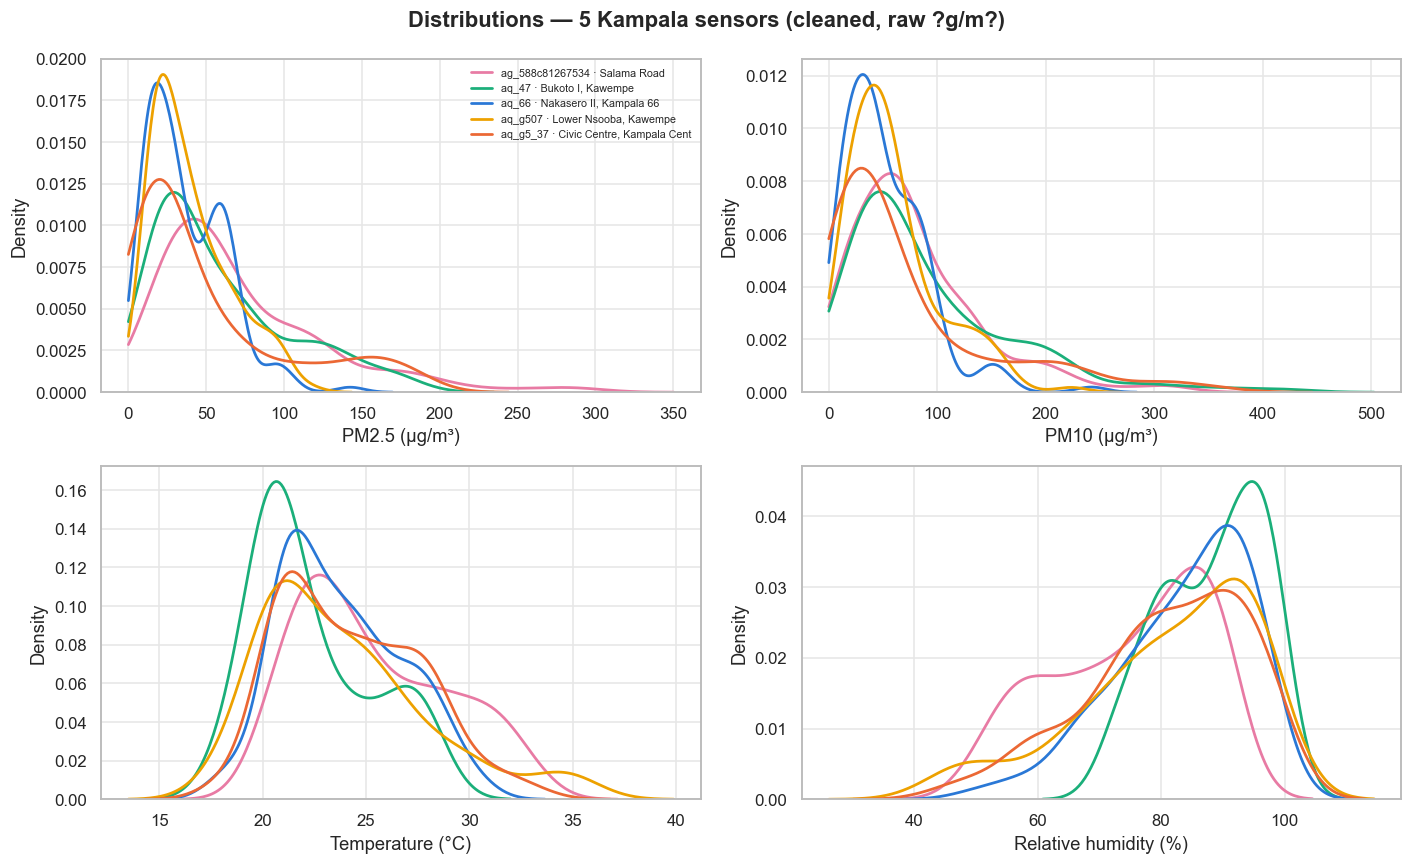

Skewness of PM2.5 (5 sensors): 1.74


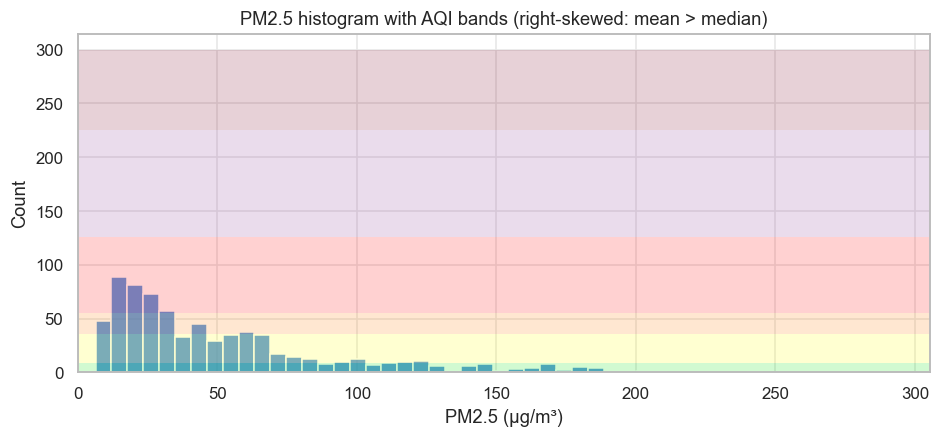

In [7]:
# 4.1 Distribution plots (PM2.5, PM10, temperature, humidity) ✅remember to change these to histograms with KDEs 
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (c, lab) in zip(axes.ravel(), [("pm2_5", "PM2.5 (µg/m³)"), ("pm10", "PM10 (µg/m³)"), ("temp", "Temperature (°C)"), ("humidity", "Relative humidity (%)")]):
    for s in eda.sensor.unique():
        sns.kdeplot(eda.loc[eda.sensor == s, c].dropna(), ax=ax, label=s, color=COLOR_OF[s], lw=1.8, warn_singular=False,
                    clip=(0, None) if c.startswith("pm") else None)
    ax.set_xlabel(lab); ax.set_ylabel("Density")
axes[0, 0].legend(fontsize=7, frameon=False)
fig.suptitle("Distributions — 5 Kampala sensors (cleaned, raw ?g/m?)", fontweight="bold"); plt.tight_layout(); savefig("eda_distributions"); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(eda.pm2_5.dropna(), bins=50, ax=ax, color=SERIES[0])
shade_aqi(ax, ax.get_ylim()[1] * 0 + 300); ax.set_xlim(0, eda.pm2_5.max() * 1.05)
ax.set_xlabel("PM2.5 (µg/m³)"); ax.set_title("PM2.5 histogram with AQI bands (right-skewed: mean > median)")
print(f"Skewness of PM2.5 (5 sensors): {eda.pm2_5.skew():.2f}")
savefig("eda_hist_pm25"); plt.show()

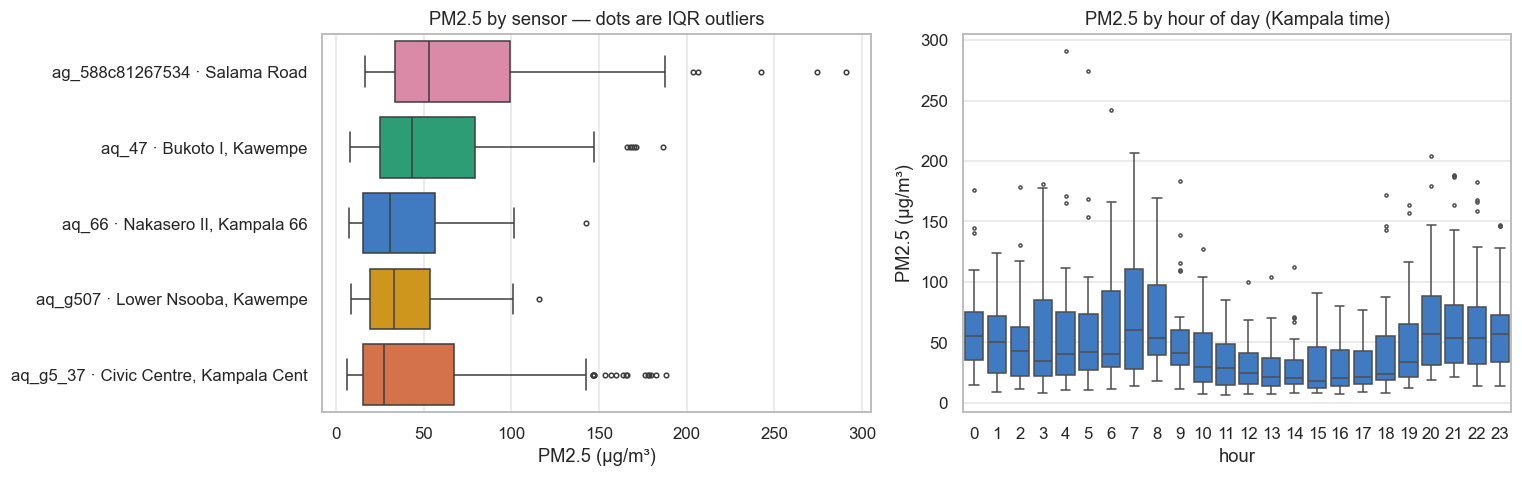

,n,iqr_outliers,robust_z_outliers,max_pm25
sensor,,,,
ag_588c81267534 · Salama Road,142,5,5,291.0
"aq_47 · Bukoto I, Kawempe",145,6,6,186.4
"aq_66 · Nakasero II, Kampala 66",147,1,1,142.4
"aq_g507 · Lower Nsooba, Kawempe",144,1,0,115.9
"aq_g5_37 · Civic Centre, Kampala Cent",147,17,25,188.2


Treatment: physically impossible values (>500) were set to NaN in §2; statistical outliers are KEPT and flagged — they coincide with morning/evening peaks, so they are plausible pollution events, and tree models are robust to them.


In [8]:
# 4.2 Box plots and outlier tracking
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=eda, y="sensor", x="pm2_5", ax=axes[0], palette=COLOR_OF, fliersize=3)
axes[0].set_xlabel("PM2.5 (µg/m³)"); axes[0].set_ylabel(""); axes[0].set_title("PM2.5 by sensor — dots are IQR outliers")
eda["hour"] = eda.datetime.dt.hour
sns.boxplot(data=eda, x="hour", y="pm2_5", ax=axes[1], color=SERIES[0], fliersize=2)
axes[1].set_title("PM2.5 by hour of day (Kampala time)"); axes[1].set_ylabel("PM2.5 (µg/m³)")
plt.tight_layout(); savefig("eda_boxplots"); plt.show()

q1, q3 = eda.groupby("sensor").pm2_5.transform(lambda s: s.quantile(.25)), eda.groupby("sensor").pm2_5.transform(lambda s: s.quantile(.75))
eda["iqr_outlier"] = (eda.pm2_5 > q3 + 1.5 * (q3 - q1)) | (eda.pm2_5 < q1 - 1.5 * (q3 - q1))
outlier_table = eda.groupby("sensor").agg(n=("pm2_5", "count"), iqr_outliers=("iqr_outlier", "sum"),
                                          robust_z_outliers=("pm25_outlier_flag", "sum"), max_pm25=("pm2_5", "max")).round(1)
display(outlier_table)
print("Treatment: physically impossible values (>500) were set to NaN in §2; statistical outliers are KEPT and flagged — "
      "they coincide with morning/evening peaks, so they are plausible pollution events, and tree models are robust to them.")

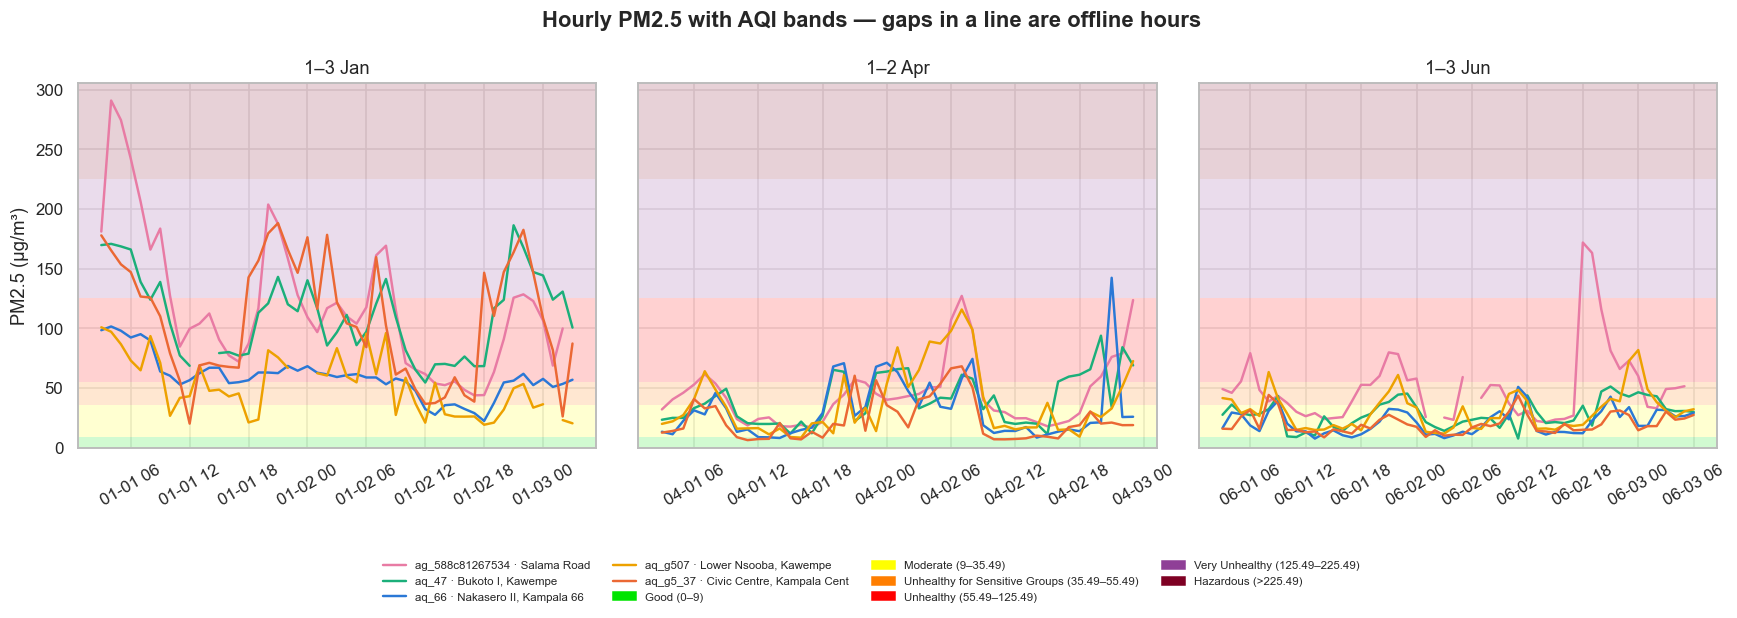

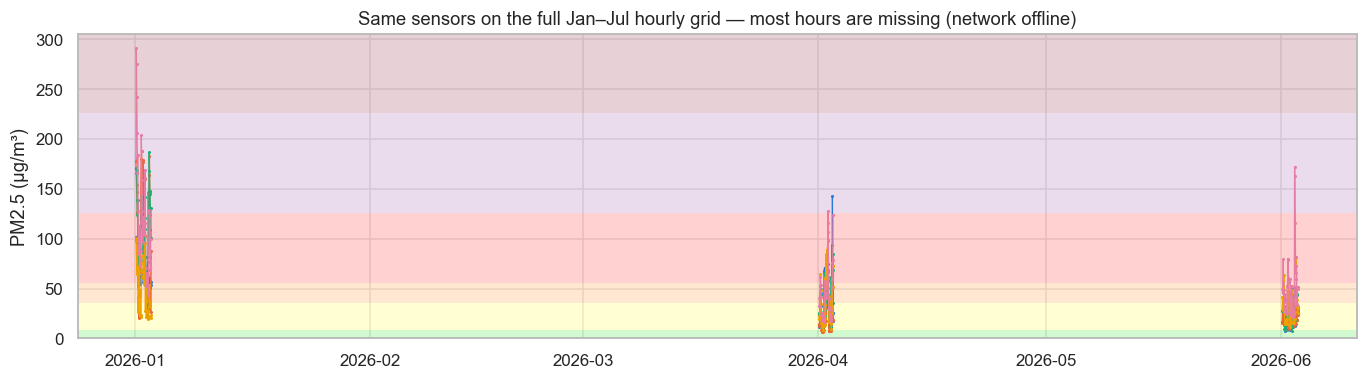

In [9]:
# 4.3 Time-series plots with AQI bands (one panel per data window, shared y-axis)
windows = [("1–3 Jan", "2026-01-01", "2026-01-03 23:00"), ("1–2 Apr", "2026-04-01", "2026-04-02 23:00"), ("1–3 Jun", "2026-06-01", "2026-06-03 23:00")]
ymax = min(eda.pm2_5.max() * 1.05, 330)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, (lab, a, b) in zip(axes, windows):
    shade_aqi(ax, ymax)
    for s in eda.sensor.unique():
        g = hourly[(hourly.device_name == [k for k, v in NAMES.items() if v == s][0]) & hourly.datetime.between(a, b)]
        ax.plot(g.datetime, g.pm2_5, color=COLOR_OF[s], label=s, lw=1.6)
    ax.set_title(lab); ax.set_ylim(0, ymax); ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("PM2.5 (µg/m³)")
fig.legend(handles=[plt.Line2D([], [], color=COLOR_OF[s], label=s) for s in eda.sensor.unique()] + aqi_legend_handles(),
           loc="lower center", ncol=4, fontsize=7.5, frameon=False, bbox_to_anchor=(0.5, -0.16))
fig.suptitle("Hourly PM2.5 with AQI bands — gaps in a line are offline hours", fontweight="bold")
plt.tight_layout(); savefig("eda_timeseries_aqi"); plt.show()

# Full Jan–Jul axis to show the offline stretches
fig, ax = plt.subplots(figsize=(15, 3.6)); shade_aqi(ax, ymax)
for d in KAMPALA:
    g = hourly[hourly.device_name == d]
    ax.plot(g.datetime, g.pm2_5, color=COLOR_OF[NAMES[d]], marker=".", ms=2, lw=0.8)
ax.set_ylim(0, ymax); ax.set_title("Same sensors on the full Jan–Jul hourly grid — most hours are missing (network offline)")
ax.set_ylabel("PM2.5 (µg/m³)"); savefig("eda_timeseries_fullrange"); plt.show()

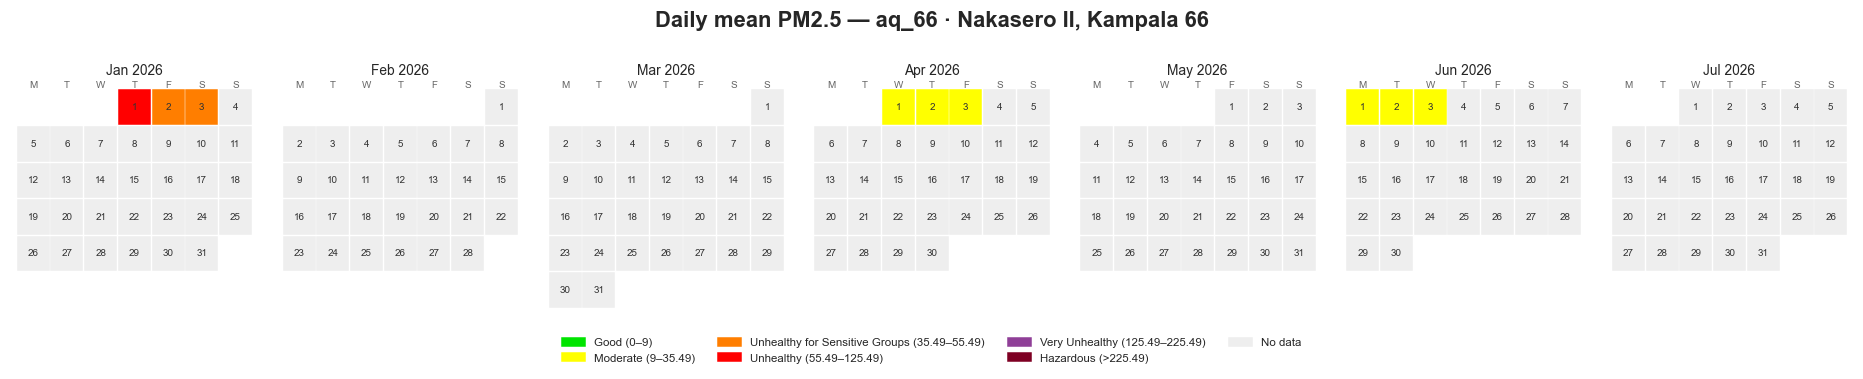

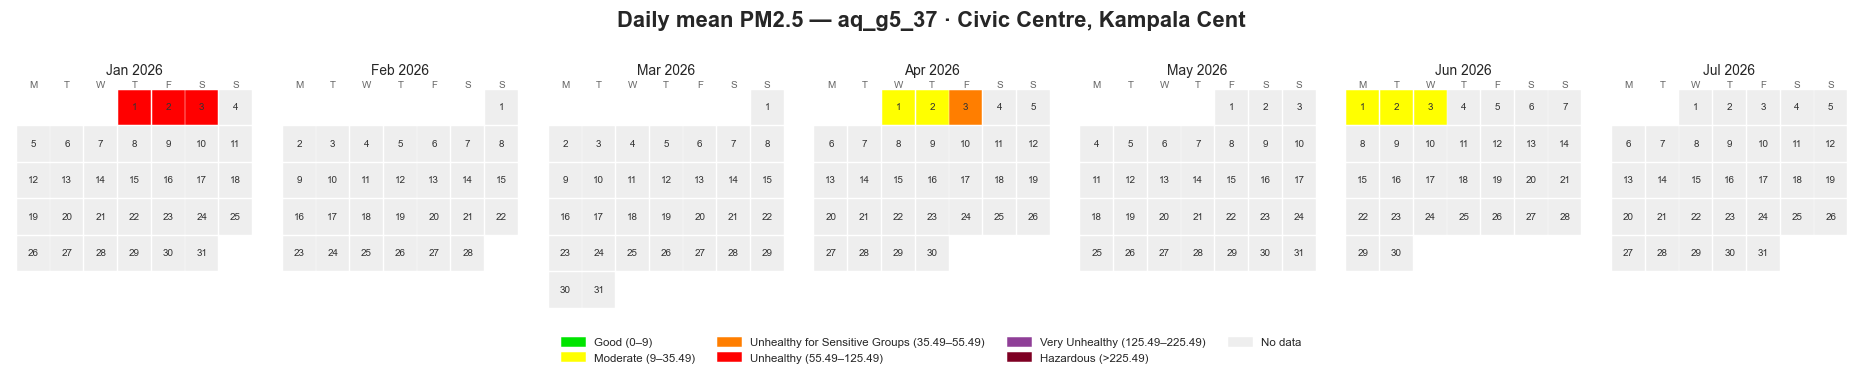

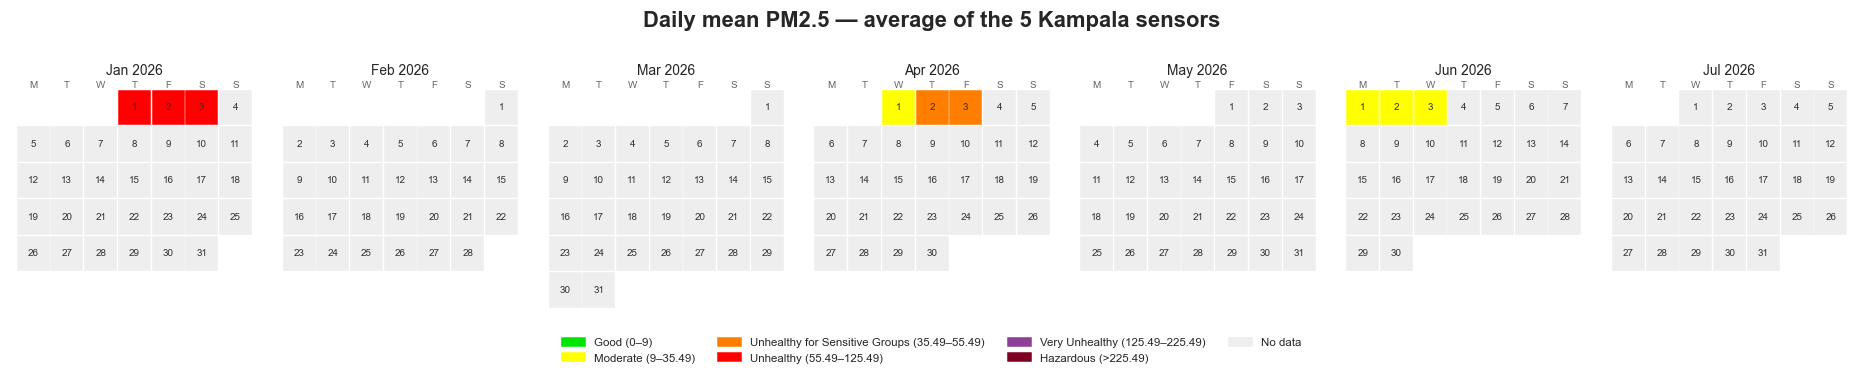

In [10]:
# 4.4 Calendar plot of daily mean PM2.5, AQI-coloured (grey = no data)
def calendar_plot(daily, months, title, fname):
    """daily: Series indexed by date -> PM2.5 µg/m³. One mini-calendar per month (rows = weeks, cols = Mon..Sun)."""
    fig, axes = plt.subplots(1, len(months), figsize=(2.3 * len(months) + 1, 3.0))
    axes = np.atleast_1d(axes)
    for ax, (y, m) in zip(axes, months):
        first = pd.Timestamp(y, m, 1); days = pd.date_range(first, first + pd.offsets.MonthEnd(0))
        for d in days:
            week = (d.day - 1 + first.weekday()) // 7
            v = daily.get(d.normalize(), np.nan)
            col = "#eeeeee" if pd.isna(v) else AQI_COLORS[int(np.digitize(v, AQI_BINS[1:-1]))]
            ax.add_patch(mpatches.Rectangle((d.weekday(), -week), 0.92, 0.92, color=col))
            ax.text(d.weekday() + .46, -week + .46, d.day, ha="center", va="center", fontsize=6.5,
                    color="white" if (not pd.isna(v) and v > 125.49) else "#333333")
        ax.set_xlim(-.2, 7.1); ax.set_ylim(-5.2, 1.1); ax.axis("off")
        ax.set_title(first.strftime("%b %Y"), fontsize=9)
        for i, wd in enumerate("MTWTFSS"): ax.text(i + .46, 1.0, wd, ha="center", fontsize=6.5, color="#666")
    fig.legend(handles=aqi_legend_handles() + [mpatches.Patch(color="#eeeeee", label="No data")],
               loc="lower center", ncol=4, fontsize=7.5, frameon=False, bbox_to_anchor=(0.5, -0.12))
    fig.suptitle(title, fontweight="bold"); plt.tight_layout(); savefig(fname); plt.show()

MONTHS_JJ = [(2026, m) for m in range(1, 8)]
for d in KAMPALA[:2]:
    daily = df[df.device_name == d].set_index("datetime").pm2_5.resample("D").mean()
    calendar_plot(daily, MONTHS_JJ, f"Daily mean PM2.5 — {NAMES[d]}", f"eda_calendar_{d}")
daily_all = eda.set_index("datetime").pm2_5.resample("D").mean()
calendar_plot(daily_all, MONTHS_JJ, "Daily mean PM2.5 — average of the 5 Kampala sensors", "eda_calendar_kampala5")

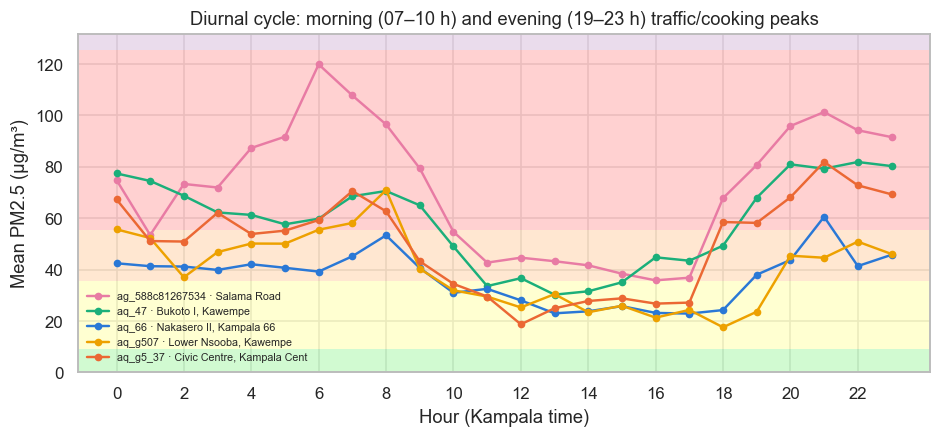

In [11]:
# 4.5 Diurnal profile — when in the day is the air worst?
prof = eda.groupby(["sensor", "hour"]).pm2_5.mean().reset_index()
fig, ax = plt.subplots(figsize=(10, 4)); shade_aqi(ax, prof.pm2_5.max() * 1.1)
for s in prof.sensor.unique():
    p = prof[prof.sensor == s]; ax.plot(p.hour, p.pm2_5, color=COLOR_OF[s], marker="o", ms=4, label=s)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hour (Kampala time)"); ax.set_ylabel("Mean PM2.5 (µg/m³)")
ax.set_ylim(0, prof.pm2_5.max() * 1.1); ax.legend(fontsize=7, frameon=False); ax.set_title("Diurnal cycle: morning (07–10 h) and evening (19–23 h) traffic/cooking peaks")
savefig("eda_diurnal"); plt.show()

### 4.6 Z-score transformation of compressed PM2.5 (all sensors)
$z = \dfrac{x - \mu}{\sigma}$, with μ and σ computed over the **high-tail-compressed PM2.5 of all sensors**. We store μ and σ — they are needed later to turn predictions back into µg/m³ ($x = z\,\sigma + \mu$).

**Interpretation:** z = 0 means "an average hour across the network"; z = +1 means one standard deviation dirtier than average; z = +2 or more is an unusually polluted hour (top ~5 % if the data were normal — but PM2.5 is right-skewed, so large positive z-values are more common than negative ones and negative z-values are bounded because concentration cannot go below 0). The z-score does **not** change the shape of the distribution or the ranking of hours; it only re-centres and re-scales so that models, especially distance-based (KNN, SVR) and regularised (Ridge) ones, see the target on a unit scale.

μ = 32.65 µg/m³   σ = 29.06 µg/m³


,z,PM2.5 µg/m³,AQI category
0,-1,3.6,Good
1,0,32.7,Moderate
2,1,61.7,Unhealthy
3,2,90.8,Unhealthy
4,3,119.8,Unhealthy
5,5,178.0,Very Unhealthy


Good/Moderate boundary (9)   → z = -0.81
USG boundary (35.49)         → z = +0.10
Unhealthy (55.49)            → z = +0.79
Very Unhealthy (125.49)      → z = +3.19


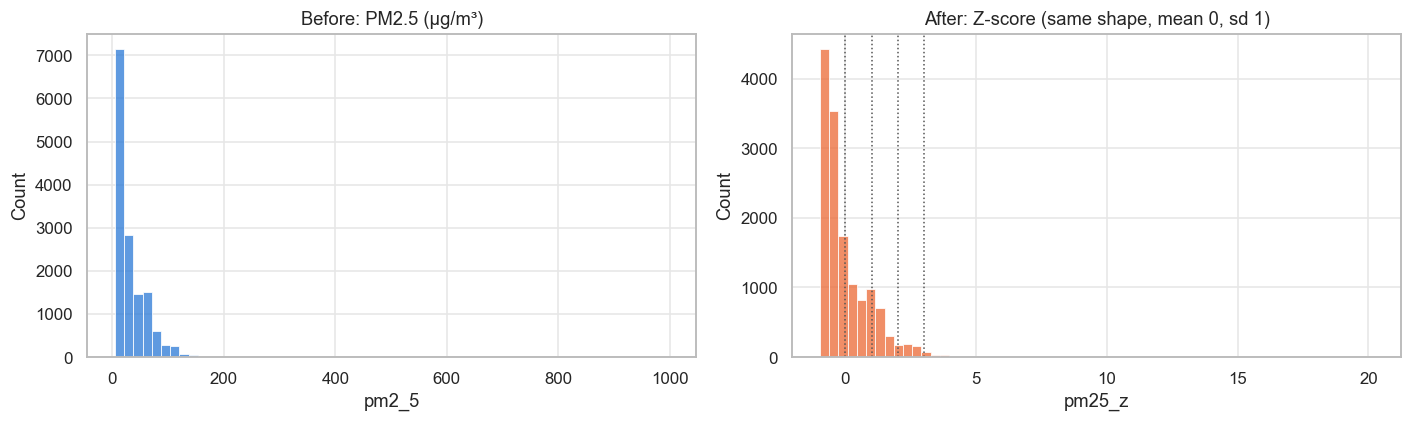

Sensors with the highest average z (persistently above the network mean):
device_name
ag_588c81267534    1.35
aq_54              1.46
aq_46              1.53
aq_70              1.86
ag_588c81266dc8    4.68
Sensors with the lowest average z:
device_name
aq_g5_93      -0.72
aq_g5_79      -0.64
airqo_g5305   -0.63
airqo_g5455   -0.58
aq_g5_97      -0.57


In [12]:
def compress_pm25(x):
    """Keep PM2.5 <=500 unchanged; logarithmically compress the excess tail."""
    x = np.asarray(x, dtype=float)
    return np.where(x <= 500, x, 500 + 50 * np.log1p((x - 500) / 50))

def expand_pm25(x):
    """Invert compress_pm25, returning concentrations in ?g/m?."""
    x = np.asarray(x, dtype=float)
    return np.where(x <= 500, x, 500 + 50 * np.expm1((x - 500) / 50))

PM_MU = float(compress_pm25(hourly.loc[hourly.is_observed == 1, "pm2_5"]).mean())
PM_SD = float(compress_pm25(hourly.loc[hourly.is_observed == 1, "pm2_5"]).std())
hourly["pm25_z"] = (compress_pm25(hourly["pm2_5_interp"]) - PM_MU) / PM_SD
df["pm25_z"] = (compress_pm25(df["pm2_5"]) - PM_MU) / PM_SD
print(f"μ = {PM_MU:.2f} µg/m³   σ = {PM_SD:.2f} µg/m³")
ref = pd.DataFrame({"z": [-1, 0, 1, 2, 3, 5]}); ref["PM2.5 µg/m³"] = (ref.z * PM_SD + PM_MU).round(1)
ref["AQI category"] = aqi_category(ref["PM2.5 µg/m³"].clip(lower=0)).astype(str)
display(ref)
for name, cut in [("Good/Moderate boundary (9)", 9), ("USG boundary (35.49)", 35.49), ("Unhealthy (55.49)", 55.49), ("Very Unhealthy (125.49)", 125.49)]:
    print(f"{name:28s} → z = {(cut - PM_MU) / PM_SD:+.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df.pm2_5.dropna(), bins=60, ax=axes[0], color=SERIES[0]); axes[0].set_title("Before: PM2.5 (µg/m³)")
sns.histplot(df.pm25_z.dropna(), bins=60, ax=axes[1], color=SERIES[1]); axes[1].set_title("After: Z-score (same shape, mean 0, sd 1)")
for z in [0, 1, 2, 3]: axes[1].axvline(z, color="#555", ls=":", lw=1)
plt.tight_layout(); savefig("eda_zscore"); plt.show()

z_by_sensor = df.groupby("device_name", observed=True).pm25_z.mean().sort_values()
print("Sensors with the highest average z (persistently above the network mean):"); print(z_by_sensor.tail(5).round(2).to_string())
print("Sensors with the lowest average z:"); print(z_by_sensor.head(5).round(2).to_string())

## 5. Feature selection and the modelling table

**Target:** `pm25_z`, the standardized, high-tail-compressed PM2.5 value. Training rows use only actually observed PM2.5; interpolated targets are not used. Sensors with >90% missing PM2.5 in their raw reported records were removed during cleaning. Missing temperature/humidity predictors for the remaining sensors are kept and handled by a median imputer with missing indicators inside each model pipeline.

**Missing-data decision:** SMOTE is intended to oversample minority classes, while this is a continuous regression task and sensor nulls are missing measurements rather than class imbalance. Applying SMOTE here would fabricate concentration labels and is not a valid imputation method. We instead keep the readings, use the existing short-gap interpolation for descriptive hourly series, and median-impute missing predictors during model fitting. Long outages remain missing and are not invented.


In [13]:
def add_features(d):
    d = d.copy()
    h = d.datetime.dt.hour
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    d["month"] = d.datetime.dt.month
    return d

NUM_FEATURES = ["temp", "humidity", "hour_sin", "hour_cos", "month"]
CAT_FEATURES = []
FEATURES = NUM_FEATURES + CAT_FEATURES
TARGET = "pm25_z"

if "hourly" not in globals():
    raise RuntimeError("`hourly` is not defined. Run the hourly-resampling cell in Section 3 (the cell that creates `hourly` and saves hourly_clean.csv.gz), then rerun this modelling cell.")
model_df = add_features(hourly[hourly.is_observed == 1])
model_df = model_df[FEATURES + [TARGET, "pm2_5", "datetime"]].reset_index(drop=True)
print(model_df.shape); display(model_df.head())

# Blocked temporal split: within every observation window, train on the FIRST day and test on the LATER day(s).
# Every season is represented in training, and every test hour lies in the future of its training hours.
model_df["window"] = model_df.datetime.dt.month
first_day = model_df.groupby("window").datetime.transform(lambda s: s.dt.normalize().min())
is_test = model_df.datetime.dt.normalize() > first_day
train = model_df[~is_test].reset_index(drop=True)
test  = model_df[is_test].reset_index(drop=True)
X_tr, y_tr, X_te, y_te = train[FEATURES], train[TARGET], test[FEATURES], test[TARGET]
groups = train.datetime.dt.strftime("%Y-%m-%d") + "_b" + (train.datetime.dt.hour // 6).astype(str)   # 6-hour blocks
print(f"Train (1 Jan, 1 Apr, 1 Jun): {len(train):,} rows | Test (2–3 Jan, 2–3 Apr, 2–3 Jun): {len(test):,} rows | CV blocks: {groups.nunique()}")
stage("features")

(14275, 8)


,temp,humidity,hour_sin,hour_cos,month,pm25_z,pm2_5,datetime
0,18.85,99.0,0.707107,7.071068e-01,4,0.146152,36.90,2026-04-01 03:00:00
1,18.85,99.0,0.866025,5.000000e-01,4,1.653193,80.70,2026-04-01 04:00:00
2,18.85,98.5,0.965926,2.588190e-01,4,0.811934,56.25,2026-04-01 05:00:00
3,18.95,98.0,1.000000,6.123234e-17,4,1.186974,67.15,2026-04-01 06:00:00
4,19.55,96.0,0.965926,-2.588190e-01,4,2.246719,97.95,2026-04-01 07:00:00


Train (1 Jan, 1 Apr, 1 Jun): 6,128 rows | Test (2–3 Jan, 2–3 Apr, 2–3 Jun): 8,147 rows | CV blocks: 12
2026-10-11 00:05:24,757 | INFO | STAGE DONE: features  (t = 24.8 s)


## 6. Models + ensembles with hyperparameter tuning
* **Validation design:** `RandomizedSearchCV` with **GroupKFold over 6-hour blocks** on the training set (neighbouring hours are highly autocorrelated; ordinary random K-fold would leak and flatter the scores). The untouched **later day(s) of each window** form the hold-out test.
* *Why not train Jan+Apr → test June?* We tried it: every model scored **R² at or below zero** on June (no better than predicting the mean) because January is twice as polluted as April/June and nothing in the features can explain that jump from only two training snapshots. That experiment is kept as a **drift case study** in §9.
* **Preprocessing (inside every pipeline):** median imputation + missing indicators → standard scaling for numeric features; `TargetEncoder` for the sensor ID.
* **Tuning objective:** RMSE (`neg_root_mean_squared_error`).

| # | Model | Hyperparameters tuned | Why these matter |
|---|---|---|---|
| 1 | Ridge regression | `alpha` | Strength of the L2 penalty: too small → overfits correlated features (temp/humidity/hour); too large → underfits |
| 2 | K-Nearest Neighbours | `n_neighbors`, `weights`, `p` | K trades variance (small K) against over-smoothing (large K); distance weighting and Manhattan vs Euclidean change what "similar hour/site" means |
| 3 | Support Vector Regression (RBF) | `C`, `epsilon`, `gamma` | C = how hard to fit every point (outlier sensitivity); ε = width of the error-free tube; γ = how local each training point's influence is |
| 4 | Decision Tree | `max_depth`, `min_samples_leaf`, `min_samples_split`, `max_features` | Depth and leaf size are the main controls of overfitting for a single tree |
| 5 | Random Forest (bagging ensemble) | `n_estimators`, `max_depth`, `max_features`, `min_samples_leaf` | More trees = stabler average; `max_features` decorrelates trees; leaf size smooths noisy sensor spikes |
| E1 | LightGBM regressor | `n_estimators`, `learning_rate`, `num_leaves`, `max_depth`, `min_child_samples` | Efficient gradient-boosted trees capture nonlinear sensor/time interactions.\n| E2 | HistGradientBoosting (boosting ensemble) | `learning_rate`, `max_iter`, `max_leaf_nodes`, `max_depth`, `l2_regularization`, `min_samples_leaf` | Learning rate × iterations is the classic speed/generalisation trade-off; leaves/depth control interaction complexity; L2 shrinks leaf values |
| E3 | Stacking ensemble (KNN + RF + HGB → Ridge) | meta-learner `alpha` | Combines models that make different kinds of errors; the Ridge meta-learner's alpha controls how much it trusts any single base model |

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV, GroupKFold, cross_val_predict
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, StackingRegressor
from lightgbm import LGBMRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import loguniform, randint, uniform

def make_pre():
    num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())])
    return ColumnTransformer([("num", num, NUM_FEATURES)])

def pipe(est): return Pipeline([("pre", make_pre()), ("model", est)])

N_JOBS = int(os.environ.get("N_JOBS", "-1"))
N_ITER = int(os.environ.get("N_ITER", "25"))
cv = GroupKFold(n_splits=4)

SEARCH = {
    "Ridge": (Ridge(), {"model__alpha": loguniform(1e-3, 1e3)}),
    "KNN": (KNeighborsRegressor(), {"model__n_neighbors": randint(3, 60), "model__weights": ["uniform", "distance"], "model__p": [1, 2]}),
    "SVR": (SVR(kernel="rbf"), {"model__C": loguniform(1e-1, 1e2), "model__epsilon": uniform(0.01, 0.5), "model__gamma": loguniform(1e-3, 1)}),
    "DecisionTree": (DecisionTreeRegressor(random_state=SEED), {"model__max_depth": randint(2, 20), "model__min_samples_leaf": randint(1, 60),
                     "model__min_samples_split": randint(2, 60), "model__max_features": [None, "sqrt", 0.5]}),
    "RandomForest": (RandomForestRegressor(random_state=SEED, n_jobs=N_JOBS), {"model__n_estimators": randint(100, 400), "model__max_depth": [None, 8, 12, 16, 24],
                     "model__max_features": ["sqrt", 0.33, 0.5, 1.0], "model__min_samples_leaf": randint(1, 20)}),
    "LightGBM": (LGBMRegressor(random_state=SEED, verbosity=-1, n_jobs=N_JOBS), {"model__n_estimators": randint(100, 500), "model__learning_rate": loguniform(0.01, 0.2), "model__num_leaves": randint(15, 64), "model__max_depth": [-1, 5, 8, 12], "model__min_child_samples": randint(10, 60)}),
    "HistGradientBoosting": (HistGradientBoostingRegressor(random_state=SEED), {"model__learning_rate": loguniform(0.01, 0.3), "model__max_iter": randint(100, 600),
                     "model__max_leaf_nodes": randint(8, 64), "model__max_depth": [None, 3, 5, 8], "model__l2_regularization": loguniform(1e-3, 10),
                     "model__min_samples_leaf": randint(10, 80)}),
}

def evaluate(name, y_true_z, y_pred_z, extra=None):
    yt, yp = expand_pm25(y_true_z * PM_SD + PM_MU), np.clip(expand_pm25(y_pred_z * PM_SD + PM_MU), 0, None)
    cat_true, cat_pred = aqi_category(yt), aqi_category(yp)
    r = {"model": name,
         "RMSE (z)": mean_squared_error(y_true_z, y_pred_z) ** .5, "MAE (z)": mean_absolute_error(y_true_z, y_pred_z),
         "R2": r2_score(y_true_z, y_pred_z),
         "RMSE (µg/m³)": mean_squared_error(yt, yp) ** .5, "MAE (µg/m³)": mean_absolute_error(yt, yp),
         "Bias (µg/m³)": float(np.mean(yp - yt)), "AQI category accuracy": float(np.mean(cat_true.astype(str) == cat_pred.astype(str)))}
    if extra: r.update(extra)
    return r

results, fitted, best_params = [], {}, {}
base = pipe(DummyRegressor(strategy="mean")).fit(X_tr, y_tr)
results.append(evaluate("Baseline (predict mean)", y_te, base.predict(X_te), {"CV RMSE (z)": np.nan, "fit time (s)": 0}))

for name, (est, grid) in SEARCH.items():
    t = time.time()
    n_iter = min(N_ITER, 12) if name in ("SVR", "RandomForest") else N_ITER
    rs = RandomizedSearchCV(pipe(est), grid, n_iter=n_iter, cv=cv, scoring="neg_root_mean_squared_error",
                            random_state=SEED, n_jobs=N_JOBS if name != "RandomForest" else 1, refit=True)
    rs.fit(X_tr, y_tr, groups=groups)
    fitted[name] = rs.best_estimator_
    best_params[name] = {k.replace("model__", ""): (round(float(v), 4) if isinstance(v, float) else v) for k, v in rs.best_params_.items()}
    results.append(evaluate(name, y_te, rs.best_estimator_.predict(X_te), {"CV RMSE (z)": -rs.best_score_, "fit time (s)": round(time.time() - t, 1)}))
    log.info(f"{name:22s} CV RMSE(z)={-rs.best_score_:.3f} | test RMSE(z)={results[-1]['RMSE (z)']:.3f} | best={best_params[name]} | {time.time()-t:.1f}s")

# Stacking ensemble on top of the tuned base models
t = time.time()
# Tune the meta-learner on out-of-fold predictions of the three tuned base models (no leakage)
bases = [("knn", fitted["KNN"]), ("rf", fitted["RandomForest"]), ("hgb", fitted["HistGradientBoosting"])]
meta_X = np.column_stack([cross_val_predict(m, X_tr, y_tr, cv=cv, groups=groups) for _, m in bases])
alpha_cv = {}
for alpha in [0.01, 0.1, 1, 10, 100]:
    alpha_cv[alpha] = np.mean([mean_squared_error(y_tr.iloc[te], Ridge(alpha=alpha).fit(meta_X[tr], y_tr.iloc[tr]).predict(meta_X[te])) ** .5
                               for tr, te in cv.split(meta_X, y_tr, groups)])
best_alpha = min(alpha_cv, key=alpha_cv.get); best_cv = alpha_cv[best_alpha]
best_stack = StackingRegressor(estimators=bases, final_estimator=Ridge(alpha=best_alpha),
                               cv=list(cv.split(X_tr, y_tr, groups)), n_jobs=1).fit(X_tr, y_tr)
fitted["Stacking"] = best_stack; best_params["Stacking"] = {"final_estimator alpha": best_alpha, "bases": "KNN + RF + HGB"}
results.append(evaluate("Stacking", y_te, best_stack.predict(X_te), {"CV RMSE (z)": best_cv, "fit time (s)": round(time.time() - t, 1)}))
log.info(f"Stacking               CV RMSE(z)={best_cv:.3f} | test RMSE(z)={results[-1]['RMSE (z)']:.3f} | alpha={best_alpha}")

res = pd.DataFrame(results).set_index("model").round(3)
res = res.sort_values("RMSE (µg/m³)")
display(res)
res.to_csv(OUT / "model_comparison.csv")
display(pd.Series(best_params, name="best hyperparameters").to_frame())
stage("modelling")

2026-10-11 00:05:36,649 | INFO | Ridge                  CV RMSE(z)=0.988 | test RMSE(z)=0.877 | best={'alpha': 659.8711} | 11.8s
2026-10-11 00:05:38,836 | INFO | KNN                    CV RMSE(z)=0.960 | test RMSE(z)=0.914 | best={'n_neighbors': 32, 'p': 2, 'weights': 'distance'} | 2.2s
2026-10-11 00:06:34,700 | INFO | SVR                    CV RMSE(z)=0.939 | test RMSE(z)=0.877 | best={'C': 1.3293, 'epsilon': 0.4854, 'gamma': 0.157} | 55.9s
2026-10-11 00:06:36,551 | INFO | DecisionTree           CV RMSE(z)=0.957 | test RMSE(z)=0.894 | best={'max_depth': 10, 'max_features': None, 'min_samples_leaf': 44, 'min_samples_split': 9} | 1.8s
2026-10-11 00:08:14,801 | INFO | RandomForest           CV RMSE(z)=0.932 | test RMSE(z)=0.878 | best={'max_depth': 12, 'max_features': 0.5, 'min_samples_leaf': 11, 'n_estimators': 187} | 98.2s
2026-10-11 00:11:14,879 | INFO | LightGBM               CV RMSE(z)=0.942 | test RMSE(z)=0.874 | best={'learning_rate': 0.0201, 'max_depth': 5, 'min_child_samples': 5

,RMSE (z),MAE (z),R2,RMSE (µg/m³),MAE (µg/m³),Bias (µg/m³),AQI category accuracy,CV RMSE (z),fit time (s)
model,,,,,,,,,
LightGBM,0.874,0.598,0.110,26.010,17.399,3.696,0.577,0.942,180.0
SVR,0.877,0.604,0.104,26.104,17.581,3.863,0.584,0.939,55.8
Ridge,0.877,0.621,0.103,26.111,18.066,3.939,0.514,0.988,11.8
RandomForest,0.878,0.596,0.102,26.113,17.357,3.522,0.557,0.932,98.2
HistGradientBoosting,0.884,0.601,0.089,26.305,17.499,3.887,0.580,0.935,80.4
DecisionTree,0.894,0.607,0.069,26.558,17.667,3.587,0.547,0.957,1.8
KNN,0.914,0.623,0.026,27.171,18.123,4.530,0.546,0.960,2.2
Stacking,0.921,0.645,0.011,27.353,18.783,6.753,0.542,0.925,27.4
Baseline (predict mean),0.928,0.701,-0.003,27.545,20.403,1.485,0.613,NaN,0.0


,best hyperparameters
Ridge,{'alpha': 659.8711}
KNN,"{'n_neighbors': 32, 'p': 2, 'weights': 'distan..."
SVR,"{'C': 1.3293, 'epsilon': 0.4854, 'gamma': 0.157}"
DecisionTree,"{'max_depth': 10, 'max_features': None, 'min_s..."
RandomForest,"{'max_depth': 12, 'max_features': 0.5, 'min_sa..."
LightGBM,"{'learning_rate': 0.0201, 'max_depth': 5, 'min..."
HistGradientBoosting,"{'l2_regularization': 0.8111, 'learning_rate':..."
Stacking,"{'final_estimator alpha': 100, 'bases': 'KNN +..."


2026-10-11 00:13:02,959 | INFO | STAGE DONE: modelling  (t = 483.0 s)


In [15]:
## 6.1 Three-way scorecard (train, CV, test; Random Forest reported separately)
# Keep the original model_comparison.csv and saved Random Forest result untouched.
# The tuned models are already fitted on X_tr; this adds their in-sample scores,
# alongside the existing GroupKFold CV score and untouched holdout test scores.
three_way_rows = []
for name, estimator in fitted.items():
    if name == "RandomForest":
        continue
    train_score = evaluate(name, y_tr, estimator.predict(X_tr))
    test_score = res.loc[name]
    three_way_rows.append({
        "model": name,
        "Train RMSE (z)": train_score["RMSE (z)"],
        "Train MAE (z)": train_score["MAE (z)"],
        "CV RMSE (z)": test_score["CV RMSE (z)"],
        "Test RMSE (z)": test_score["RMSE (z)"],
        "Test MAE (z)": test_score["MAE (z)"],
        "Test RMSE (raw units)": test_score[next(c for c in res.columns if c.startswith("RMSE (") and "z" not in c)],
        "Test MAE (raw units)": test_score[next(c for c in res.columns if c.startswith("MAE (") and "z" not in c)],
        "Test R2": test_score["R2"],
    })
three_way = pd.DataFrame(three_way_rows).set_index("model").sort_values("Test RMSE (raw units)").round(3)
display(three_way)
three_way.to_csv(OUT / "model_comparison_three_way.csv")


,Train RMSE (z),Train MAE (z),CV RMSE (z),Test RMSE (z),Test MAE (z),Test RMSE (raw units),Test MAE (raw units),Test R2
model,,,,,,,,
LightGBM,0.875,0.541,0.942,0.874,0.598,26.010,17.399,0.110
SVR,0.896,0.575,0.939,0.877,0.604,26.104,17.581,0.104
Ridge,0.955,0.627,0.988,0.877,0.621,26.111,18.066,0.103
HistGradientBoosting,0.878,0.539,0.935,0.884,0.601,26.305,17.499,0.089
DecisionTree,0.876,0.537,0.957,0.894,0.607,26.558,17.667,0.069
KNN,0.476,0.217,0.960,0.914,0.623,27.171,18.123,0.026
Stacking,0.706,0.453,0.925,0.921,0.645,27.353,18.783,0.011


### Why these metrics?
* **RMSE** (primary, used for tuning and model choice): squares the errors, so it punishes large misses most. For public-health warnings, missing a 150 µg/m³ spike is far worse than being 5 µg/m³ off on a clean day — RMSE reflects that.
* **MAE**: the typical size of an error in µg/m³; robust to a few huge misses. If MAE ≪ RMSE the model is mostly fine but has a few big misses (spikes).
* **R²**: share of the variation in PM2.5 the model explains compared with always predicting the mean (R² = 0). Negative R² = worse than the mean.
* **Bias (mean error)**: positive → over-predicts (false alarms); negative → under-predicts (dangerous for health warnings).
* **AQI category accuracy**: does the forecast land in the correct colour band? This is what NEMA, KCCA or a hospital actually act on.
* *When would a different metric be better?* **MAPE** is unusable on z-scores (division by values near 0) and unstable for very clean hours; **MAE/median-AE** would be preferred if spikes were sensor glitches rather than real events; a **classification metric (F1/recall on 'Unhealthy' or worse)** would be preferred if the product were an alert system rather than a concentration forecast.
* Reporting in both **z units** (what the model optimises) and **µg/m³** (what people understand) — the two are linked by RMSE(µg/m³) = RMSE(z) × σ.

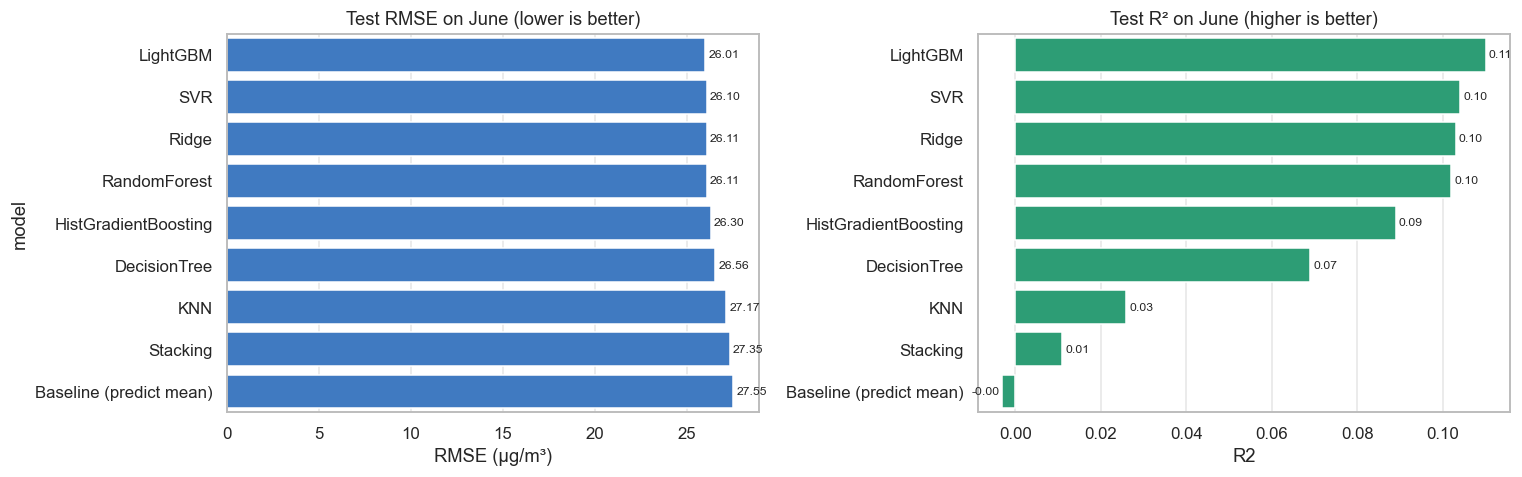

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_res = res.reset_index()
order = plot_res.sort_values("RMSE (µg/m³)").model
sns.barplot(data=plot_res, y="model", x="RMSE (µg/m³)", order=order, ax=axes[0], color=SERIES[0])
sns.barplot(data=plot_res, y="model", x="R2", order=order, ax=axes[1], color=SERIES[2])
for ax in axes:
    for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8, padding=2)
axes[0].set_title("Test RMSE on June (lower is better)"); axes[1].set_title("Test R² on June (higher is better)")
axes[1].set_ylabel(""); plt.tight_layout(); savefig("model_comparison"); plt.show()

2026-10-11 00:13:15,302 | INFO | BEST MODEL: LightGBM


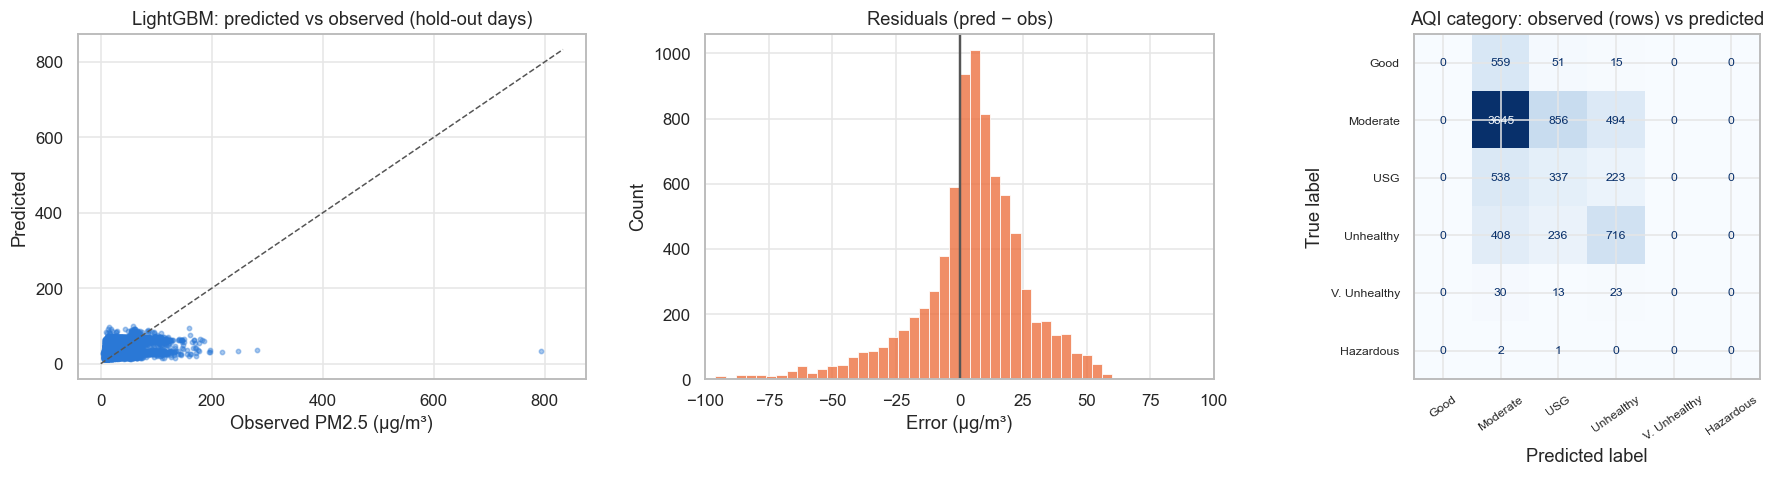

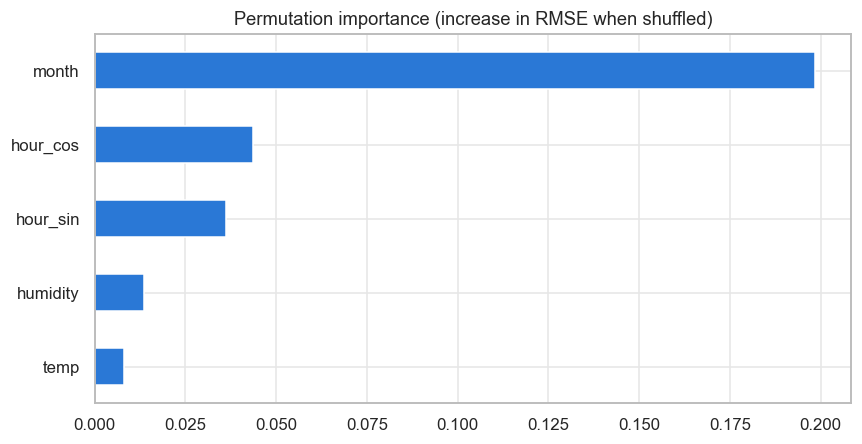

In [17]:
BEST_NAME = res.drop(index="Baseline (predict mean)")["RMSE (µg/m³)"].idxmin()
best_model = fitted[BEST_NAME]
log.info(f"BEST MODEL: {BEST_NAME}")
pred_te = best_model.predict(X_te)
yt, yp = expand_pm25(y_te * PM_SD + PM_MU), np.clip(expand_pm25(pred_te * PM_SD + PM_MU), 0, None)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
lim = max(yt.max(), yp.max()) * 1.05
axes[0].scatter(yt, yp, s=8, alpha=.4, color=SERIES[0]); axes[0].plot([0, lim], [0, lim], color="#555", ls="--", lw=1)
axes[0].set_xlabel("Observed PM2.5 (µg/m³)"); axes[0].set_ylabel("Predicted"); axes[0].set_title(f"{BEST_NAME}: predicted vs observed (hold-out days)")
sns.histplot(yp - yt, bins=np.arange(-100, 101, 4), ax=axes[1], color=SERIES[1]); axes[1].axvline(0, color="#555")
axes[1].set_title("Residuals (pred − obs)"); axes[1].set_xlabel("Error (µg/m³)"); axes[1].set_xlim(-100, 100)
from sklearn.metrics import ConfusionMatrixDisplay
SHORT = dict(zip(AQI_LABELS, ["Good", "Moderate", "USG", "Unhealthy", "V. Unhealthy", "Hazardous"]))
ConfusionMatrixDisplay.from_predictions(aqi_category(yt).astype(str).map(SHORT), aqi_category(yp).astype(str).map(SHORT), labels=list(SHORT.values()),
                                        ax=axes[2], colorbar=False, xticks_rotation=35, cmap="Blues", text_kw={"fontsize": 8})
axes[2].set_title("AQI category: observed (rows) vs predicted"); axes[2].tick_params(labelsize=8)
plt.tight_layout(); savefig("best_model_diagnostics"); plt.show()

# Permutation importance — what drives the best model
from sklearn.inspection import permutation_importance
pi = permutation_importance(best_model, X_te, y_te, n_repeats=5, random_state=SEED, scoring="neg_root_mean_squared_error", n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
imp.sort_values(ascending=False).rename("RMSE increase (z)").to_csv(OUT / "feature_importance.csv")
fig, ax = plt.subplots(figsize=(8, 4.2)); imp.plot.barh(ax=ax, color=SERIES[0]); ax.set_title("Permutation importance (increase in RMSE when shuffled)")
plt.tight_layout(); savefig("feature_importance"); plt.show()

## 7. Save the best model
The final artefact is the winning pipeline **re-fitted on all observed data (Jan + Apr + Jun)** with its tuned hyperparameters, so the August forecast uses the most recent information. The bundle stores everything needed to use it: the pipeline (preprocessing + model), the Z-score μ/σ for inverse transformation, the feature list, AQI bands and test metrics.

In [18]:
final_model = sklearn.base.clone(best_model)
if isinstance(final_model, StackingRegressor):          # CV splits must be rebuilt for the larger dataset
    final_model.set_params(cv=list(GroupKFold(n_splits=5).split(model_df[FEATURES], model_df[TARGET], model_df.datetime.dt.date.astype(str))))
final_model.fit(model_df[FEATURES], model_df[TARGET])
bundle = {"model": final_model, "model_name": BEST_NAME, "features": FEATURES, "num_features": NUM_FEATURES, "cat_features": CAT_FEATURES,
          "target": TARGET, "pm25_mean": PM_MU, "pm25_std": PM_SD, "pm25_transform": "identity_to_500_then_log1p_excess_scale_50", "aqi_bins": AQI_BINS, "aqi_labels": AQI_LABELS,
          "best_params": best_params[BEST_NAME], "test_metrics_holdout": res.loc[BEST_NAME].to_dict(),
          "trained_on": "observed hours 2026-01-01..2026-06-03", "sklearn_version": sklearn.__version__}
MODEL_PATH = OUT / "best_pm25_model.joblib"
joblib.dump(bundle, MODEL_PATH, compress=3)
log.info(f"Saved model bundle → {MODEL_PATH} ({MODEL_PATH.stat().st_size/1e6:.2f} MB)")

# reload check — proves the artefact works on its own
reloaded = joblib.load(MODEL_PATH)
assert np.allclose(reloaded["model"].predict(X_te.head(20)), final_model.predict(X_te.head(20)))
print("Reload check passed.")
stage("save_model")

2026-10-11 00:13:27,933 | INFO | Saved model bundle → outputs\best_pm25_model.joblib (0.13 MB)
Reload check passed.
2026-10-11 00:13:28,070 | INFO | STAGE DONE: save_model  (t = 508.1 s)


## 8. Forecasting August 2026 with the saved model
* **Inputs for the future:** calendar features are computed from the date; calendar features are computed from the date; August is a dry-season month. Temperature and humidity in the future are not in our data, so we use each sensor's **hour-of-day climatology** (median temp/RH observed at that hour); a production system would plug in a weather forecast here.
* **Hourly forecast:** every hour of **Saturday 1 August 2026** (first full day).
* **Daily forecast:** mean of the hourly predictions for the **first two full weeks of August = Mon 3 – Sun 16 Aug 2026** (1 Aug is a Saturday, so 1–2 Aug do not form a full week). Change `DAILY_START` to `2026-08-01` for a 1–14 Aug window.
* **Inverse transform:** PM2.5 = z × σ + μ, clipped at 0.
* **Why the daily values are flat across the fortnight:** every input that changes from day to day (weather, day-of-week) is either unknown for August or could not be learned from only 8 days of history. The model therefore predicts each sensor's *typical* August day; the information is in the **differences between sensors** and in the **hour-of-day shape**. Feeding a real weather forecast into `temp`/`humidity` is the first upgrade for production.

In [19]:
model_b = joblib.load(MODEL_PATH)
mdl, MU, SD = model_b["model"], model_b["pm25_mean"], model_b["pm25_std"]

obs = df.copy(); obs["hour"] = obs.datetime.dt.hour
clim_dev = obs.groupby(["device_name", "hour"], observed=True)[["temp", "humidity"]].median()
clim_all = obs.groupby("hour")[["temp", "humidity"]].median()

DAILY_START, DAILY_END = "2026-08-03", "2026-08-16"
future_hours = pd.date_range("2026-08-01 00:00", f"{DAILY_END} 23:00", freq="h")
fut = pd.MultiIndex.from_product([static.index.astype(str), future_hours], names=["device_name", "datetime"]).to_frame(index=False)
fut = fut.merge(static.reset_index().assign(device_name=lambda d: d.device_name.astype(str)), on="device_name", how="left")
fut["hour"] = fut.datetime.dt.hour
fut = fut.merge(clim_dev.reset_index().assign(device_name=lambda d: d.device_name.astype(str)), on=["device_name", "hour"], how="left")
for c in ["temp", "humidity"]:
    fut[c] = fut[c].fillna(fut.hour.map(clim_all[c]))
fut = add_features(fut)
fut["pred_z"] = mdl.predict(fut[model_b["features"]])
fut["pred_pm25"] = np.clip(expand_pm25(fut.pred_z * SD + MU), 0, None)
fut["aqi"] = aqi_category(fut.pred_pm25)

hourly_aug1 = fut[fut.datetime.dt.date == pd.Timestamp("2026-08-01").date()][["device_name", "site_name", "datetime", "pred_z", "pred_pm25", "aqi"]]
daily_aug = (fut[fut.datetime.between(DAILY_START, f"{DAILY_END} 23:00")].assign(date=lambda d: d.datetime.dt.normalize())
             .groupby(["device_name", "site_name", "date"], observed=True)[["pred_z", "pred_pm25"]].mean().reset_index())
daily_aug["aqi"] = aqi_category(daily_aug.pred_pm25)
hourly_aug1.to_csv(OUT / "forecast_hourly_2026-08-01.csv", index=False)
daily_aug.to_csv(OUT / "forecast_daily_2026-08-03_to_16.csv", index=False)
print(f"Hourly rows (1 Aug): {len(hourly_aug1):,} | Daily rows (3–16 Aug): {len(daily_aug):,}")
print("Daily forecast AQI mix (all sensors):"); print(daily_aug.aqi.value_counts().reindex(AQI_LABELS).fillna(0).astype(int).to_string())
display(daily_aug.head())

Hourly rows (1 Aug): 3,576 | Daily rows (3–16 Aug): 2,086
Daily forecast AQI mix (all sensors):
aqi
Good                                 0
Moderate                          2086
Unhealthy for Sensitive Groups       0
Unhealthy                            0
Very Unhealthy                       0
Hazardous                            0


,device_name,site_name,date,pred_z,pred_pm25,aqi
0,ag_588c8125eca4,Kyebando,2026-08-03,-0.146184,28.403665,Moderate
1,ag_588c8125eca4,Kyebando,2026-08-04,-0.146184,28.403665,Moderate
2,ag_588c8125eca4,Kyebando,2026-08-05,-0.146184,28.403665,Moderate
3,ag_588c8125eca4,Kyebando,2026-08-06,-0.146184,28.403665,Moderate
4,ag_588c8125eca4,Kyebando,2026-08-07,-0.146184,28.403665,Moderate


Forecast showcase sensors (one per zone):


,site_name
device_name,
airqo_g5282,"Lorry Park, Fort Portal"
aq_66,"Nakasero II, Kampala 66"
aq_g5_37,"Civic Centre, Kampala Central"
aq_47,"Bukoto I, Kawempe"
aq_58,"Nansana east ward, Wakiso"


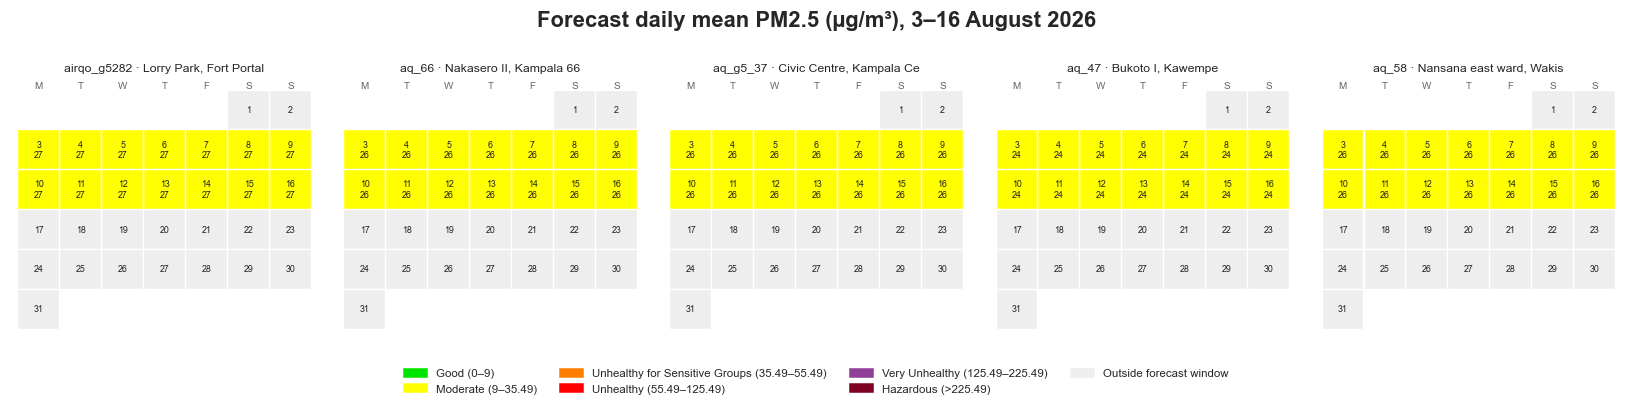

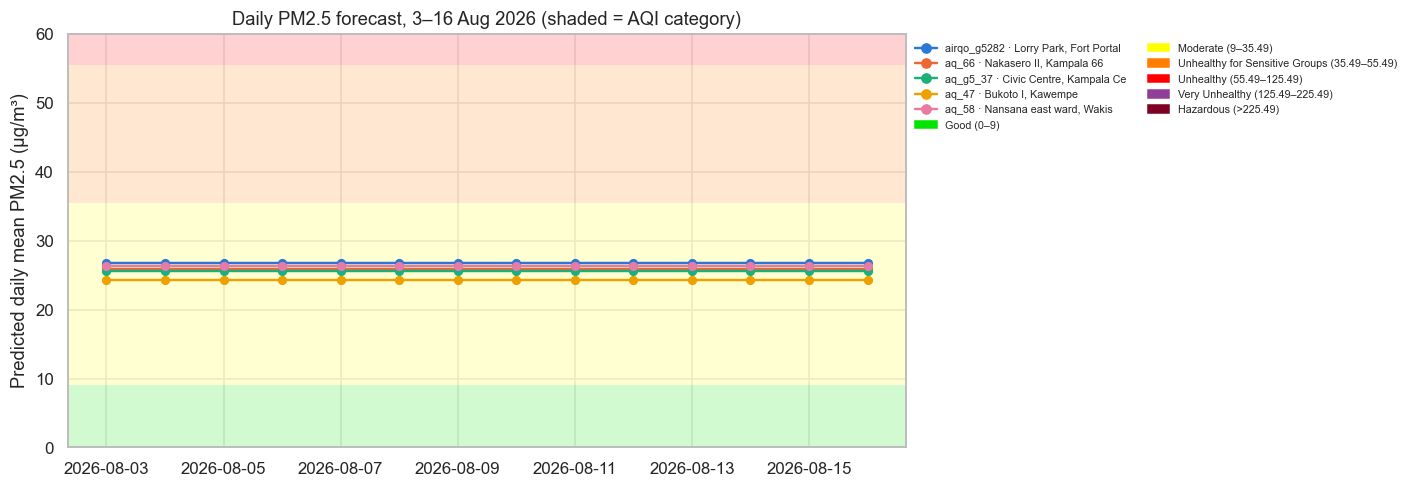

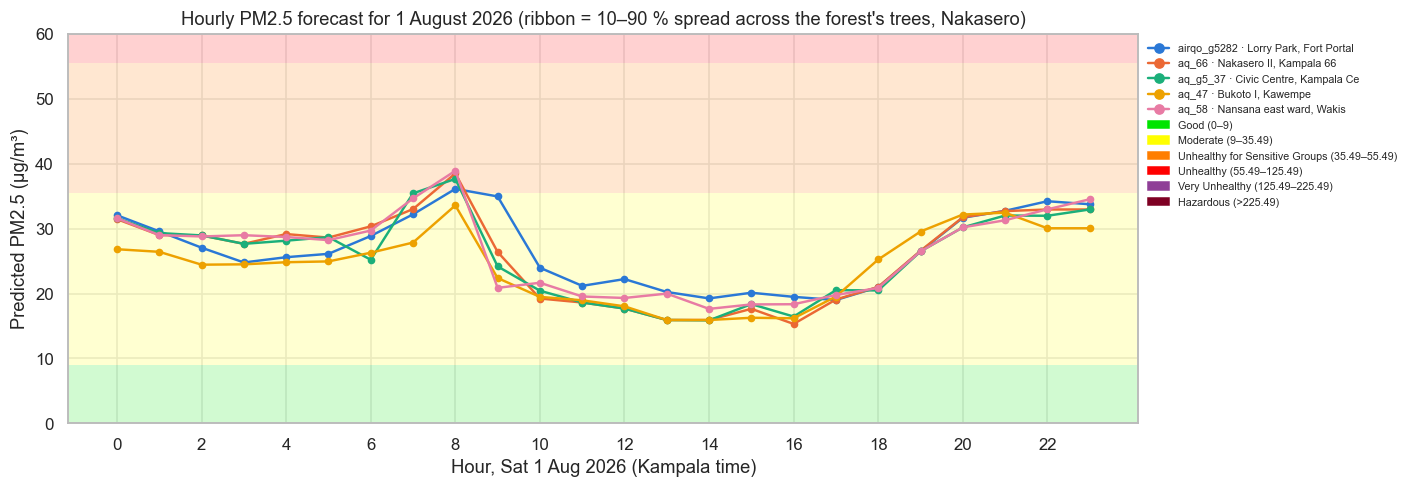

2026-10-11 00:13:43,645 | INFO | STAGE DONE: forecast  (t = 523.7 s)


In [20]:
# Showcase the five sensors with the most observed PM2.5 readings.
counts = df.groupby("device_name", observed=True).pm2_5.count()
PICK = counts.nlargest(5).index.astype(str).tolist()
PNAME = {d: f"{d} · {str(static.loc[d, 'site_name'])[:24]}" for d in PICK}
print("Forecast showcase sensors (one per zone):"); display(static.loc[PICK, ["site_name"]])

# Calendar plot of daily forecasts
fig, axes = plt.subplots(1, len(PICK), figsize=(3.0 * len(PICK), 3.2))
first = pd.Timestamp("2026-08-01")
for ax, d in zip(axes, PICK):
    s = daily_aug[daily_aug.device_name == d].set_index("date").pred_pm25
    for day in pd.date_range(first, "2026-08-31"):
        week = (day.day - 1 + first.weekday()) // 7; v = s.get(day, np.nan)
        col = "#eeeeee" if pd.isna(v) else AQI_COLORS[int(np.digitize(v, AQI_BINS[1:-1]))]
        ax.add_patch(mpatches.Rectangle((day.weekday(), -week), .92, .92, color=col))
        ax.text(day.weekday() + .46, -week + .46, f"{day.day}\n{v:.0f}" if not pd.isna(v) else day.day, ha="center", va="center", fontsize=5.8, color="#222")
    for i, wd in enumerate("MTWTFSS"): ax.text(i + .46, 1.0, wd, ha="center", fontsize=6.5, color="#666")
    ax.set_xlim(-.2, 7.1); ax.set_ylim(-5.2, 1.2); ax.axis("off"); ax.set_title(PNAME[d], fontsize=8)
fig.legend(handles=aqi_legend_handles() + [mpatches.Patch(color="#eeeeee", label="Outside forecast window")], loc="lower center", ncol=4, fontsize=7.5, frameon=False, bbox_to_anchor=(.5, -.14))
fig.suptitle("Forecast daily mean PM2.5 (µg/m³), 3–16 August 2026", fontweight="bold"); plt.tight_layout(); savefig("forecast_calendar"); plt.show()

# Time series of daily forecasts with AQI bands
fig, ax = plt.subplots(figsize=(13, 4.6))
ym = max(60, daily_aug[daily_aug.device_name.isin(PICK)].pred_pm25.max() * 1.15); shade_aqi(ax, ym)
for i, d in enumerate(PICK):
    s = daily_aug[daily_aug.device_name == d]; ax.plot(s.date, s.pred_pm25, marker="o", ms=5, color=SERIES[i], label=PNAME[d])
ax.set_ylim(0, ym); ax.set_ylabel("Predicted daily mean PM2.5 (µg/m³)")
ax.legend(handles=[plt.Line2D([], [], color=SERIES[i], marker="o", label=PNAME[d]) for i, d in enumerate(PICK)] + aqi_legend_handles(), fontsize=7, ncol=2, frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title("Daily PM2.5 forecast, 3–16 Aug 2026 (shaded = AQI category)"); plt.tight_layout(); savefig("forecast_daily_timeseries"); plt.show()

# Hourly forecast for 1 Aug
fig, ax = plt.subplots(figsize=(13, 4.6))
h1 = hourly_aug1[hourly_aug1.device_name.isin(PICK)]
ym = max(60, h1.pred_pm25.max() * 1.15); shade_aqi(ax, ym)
# spread of the individual trees (only for forest-type models): a rough 10–90 % band, not a calibrated interval.
# Drawn for the Kampala sensor only, to keep the chart readable.
est = mdl[-1] if hasattr(mdl, "steps") else None
for i, d in enumerate(PICK):
    s = h1[h1.device_name == d]
    if d == "aq_66" and est is not None and hasattr(est, "estimators_") and isinstance(est, RandomForestRegressor):
        Xt = mdl[:-1].transform(fut.loc[s.index, model_b["features"]])
        tree_z = np.stack([t.predict(Xt) for t in est.estimators_])
        lo_, hi_ = np.clip(expand_pm25(np.percentile(tree_z, [10, 90], axis=0) * SD + MU), 0, None)
        ax.fill_between(s.datetime.dt.hour, lo_, hi_, color=SERIES[i], alpha=.12, lw=0)
    ax.plot(s.datetime.dt.hour, s.pred_pm25, marker="o", ms=4, color=SERIES[i], label=PNAME[d])
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hour, Sat 1 Aug 2026 (Kampala time)"); ax.set_ylabel("Predicted PM2.5 (µg/m³)"); ax.set_ylim(0, ym)
ax.legend(handles=[plt.Line2D([], [], color=SERIES[i], marker="o", label=PNAME[d]) for i, d in enumerate(PICK)] + aqi_legend_handles(), fontsize=7, ncol=1, frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title("Hourly PM2.5 forecast for 1 August 2026 (ribbon = 10–90 % spread across the forest's trees, Nakasero)"); plt.tight_layout(); savefig("forecast_hourly_aug1"); plt.show()
stage("forecast")

### (Bonus) Map: sensors in the *Unhealthy for Sensitive Groups* to *Very Unhealthy* range at 13:00 on 1 Aug 2026
Uses a Uganda shapefile from `shapefiles/` (drop in GADM `gadm41_UGA_1.shp` or the UBOS districts file for district borders). If the folder is empty, the notebook **writes one itself** from the Natural Earth (public-domain) Uganda boundary embedded below, so the map works offline and on RunPod. If geopandas is unavailable the sensors are still plotted on lat/lon axes — the cell never fails.

In [21]:
# Geographic map omitted: coordinates are excluded from this pipeline.


## 9. Monitoring with Evidently AI — data drift and model drift
* **Run A — model monitoring.** *Reference* = training hours (first day of each window) with **out-of-fold** predictions (honest, not in-sample error); *current* = the hold-out hours with the model's predictions.
* **Run B — seasonal drift case study.** *Reference* = January window, *current* = June window (features + target). This is what a model trained in January would face in June.
* **Data drift:** for each feature (and the target) Evidently compares the reference vs current distribution with a statistical test (Kolmogorov–Smirnov p-value for numeric columns with < 1000 rows, Wasserstein distance for larger samples, chi-square / Jensen-Shannon for categorical) and marks the column as drifted when the test crosses its threshold. The dataset is declared drifted when the **share of drifted columns ≥ 0.5**.
* **Model drift:** the same regression-quality metrics (RMSE, MAE, mean error, R², max error) computed on reference and current; a clear rise in error = the model is degrading. *Prediction drift* (drift of the prediction column itself) is an early warning that works even before ground truth arrives.
Wrapped in `try/except`: if Evidently fails (e.g. a version mismatch on RunPod) the pipeline continues.

In [22]:
drift_summary = {}
try:
    from evidently import Report, Dataset, DataDefinition, Regression
    from evidently.presets import DataDriftPreset, RegressionPreset
    ref_df = train[NUM_FEATURES + [TARGET]].copy()
    ref_df["prediction"] = cross_val_predict(best_model, X_tr, y_tr, cv=GroupKFold(n_splits=4), groups=groups)
    cur_df = test[NUM_FEATURES + [TARGET]].copy(); cur_df["prediction"] = pred_te
    ddef = DataDefinition(numerical_columns=NUM_FEATURES + [TARGET, "prediction"], regression=[Regression(target=TARGET, prediction="prediction")])
    ref_ds, cur_ds = Dataset.from_pandas(ref_df, data_definition=ddef), Dataset.from_pandas(cur_df, data_definition=ddef)

    drift_cols = ["temp", "humidity", "hour_sin", "hour_cos", TARGET, "prediction"]
    drift_snap = Report([DataDriftPreset(columns=drift_cols)]).run(cur_ds, ref_ds)
    drift_snap.save_html(str(OUT / "evidently_data_drift.html"))
    quality_cur = Report([RegressionPreset()]).run(cur_ds, ref_ds); quality_cur.save_html(str(OUT / "evidently_model_quality.html"))
    quality_ref = Report([RegressionPreset()]).run(ref_ds, None)

    rows = []
    for m in drift_snap.dict()["metrics"]:
        n = m["metric_name"]
        if n.startswith("DriftedColumnsCount"):
            drift_summary["drifted_columns"] = m["value"]
        elif n.startswith("ValueDrift"):
            col = n.split("column=")[1].split(",")[0]; method = n.split("method=")[1].split(",")[0]
            thr = float(n.split("threshold=")[1].rstrip(")"))
            val = float(m["value"]); is_p = "p_value" in method
            rows.append({"column": col, "test": method, "value": round(val, 4), "threshold": thr,
                         "drift detected": (val < thr) if is_p else (val > thr)})
    drift_table = pd.DataFrame(rows); display(drift_table)
    print("Dataset-level:", drift_summary.get("drifted_columns"))

    def qdict(snap):
        out = {}
        for m in snap.dict()["metrics"]:
            k = m["metric_name"].split("(")[0]; v = m["value"]
            out[k] = v["mean"] if isinstance(v, dict) and "mean" in v else v
        return out
    qr, qc = qdict(quality_ref), qdict(quality_cur)
    model_drift = pd.DataFrame({"reference (Jan+Apr, out-of-fold)": qr, "current (June)": qc}).loc[["RMSE", "MAE", "MeanError", "R2Score", "AbsMaxError"]].astype(float).round(3)
    model_drift["change"] = (model_drift.iloc[:, 1] - model_drift.iloc[:, 0]).round(3)
    model_drift.columns = ["reference (train, out-of-fold)", "current (hold-out)", "change"]
    display(model_drift)

    # Run B: seasonal drift — January window vs June window
    jan = model_df[model_df.window == 1][["temp", "humidity", "hour_sin", "hour_cos", TARGET]]
    jun = model_df[model_df.window == 6][["temp", "humidity", "hour_sin", "hour_cos", TARGET]]
    sdef = DataDefinition(numerical_columns=list(jan.columns))
    season_snap = Report([DataDriftPreset()]).run(Dataset.from_pandas(jun, data_definition=sdef), Dataset.from_pandas(jan, data_definition=sdef))
    season_snap.save_html(str(OUT / "evidently_seasonal_drift_jan_vs_jun.html"))
    srows = []
    for m in season_snap.dict()["metrics"]:
        n = m["metric_name"]
        if n.startswith("ValueDrift"):
            srows.append({"column": n.split("column=")[1].split(",")[0], "test": n.split("method=")[1].split(",")[0],
                          "value": round(float(m["value"]), 4), "threshold": float(n.split("threshold=")[1].rstrip(")"))})
        elif n.startswith("DriftedColumnsCount"):
            drift_summary["seasonal_drifted_columns"] = m["value"]
    season_table = pd.DataFrame(srows)
    season_table["drift detected"] = np.where(season_table.test.str.contains("p_value"), season_table.value < season_table.threshold, season_table.value > season_table.threshold)
    print("Run B — January vs June:"); display(season_table)
    print(f"Mean PM2.5: Jan {model_df[model_df.window==1].pm2_5.mean():.1f} µg/m³ vs Jun {model_df[model_df.window==6].pm2_5.mean():.1f} µg/m³")
    drift_summary["seasonal_drift"] = season_table.to_dict(orient="records")
    drift_summary["model_drift"] = model_drift.to_dict()
    drift_summary["feature_drift"] = drift_table.to_dict(orient="records")
    log.info("Evidently reports saved (evidently_data_drift.html, evidently_model_quality.html)")
except Exception as e:
    log.warning(f"Evidently step skipped: {type(e).__name__}: {e}")
stage("monitoring")

,column,test,value,threshold,drift detected
0,temp,Wasserstein distance (normed),0.1602,0.1,True
1,humidity,Wasserstein distance (normed),0.2614,0.1,True
2,hour_sin,Wasserstein distance (normed),0.1789,0.1,True
3,hour_cos,Wasserstein distance (normed),0.3398,0.1,True
4,pm25_z,Wasserstein distance (normed),0.0831,0.1,False
5,prediction,Wasserstein distance (normed),0.3545,0.1,True


Dataset-level: {'count': 5.0, 'share': 0.8333333333333334}


,"reference (train, out-of-fold)",current (hold-out),change
RMSE,0.944,0.874,-0.070
MAE,0.589,0.598,0.009
MeanError,-0.098,0.128,0.226
R2Score,0.249,0.110,-0.139
AbsMaxError,20.533,19.326,-1.207


Run B — January vs June:


,column,test,value,threshold,drift detected
0,temp,Wasserstein distance (normed),0.3673,0.1,True
1,humidity,Wasserstein distance (normed),0.5878,0.1,True
2,hour_sin,Wasserstein distance (normed),0.0264,0.1,False
3,hour_cos,Wasserstein distance (normed),0.0182,0.1,False
4,pm25_z,Wasserstein distance (normed),0.7898,0.1,True


Mean PM2.5: Jan 48.7 µg/m³ vs Jun 24.6 µg/m³
2026-10-11 00:13:59,975 | INFO | Evidently reports saved (evidently_data_drift.html, evidently_model_quality.html)
2026-10-11 00:13:59,977 | INFO | STAGE DONE: monitoring  (t = 540.0 s)


**How to read this for our problem**
* **`month` / calendar features drift by construction** — expected, not alarming.
* **Temperature/humidity drift** means the weather regime changed — the model is then operating in conditions it saw less of; watch its error.
* **Target drift (pm25_z)** means pollution levels themselves changed (e.g. dry-season burning) — this is *concept/label* change the model must keep up with.
* **Prediction drift** without target data is the first alarm you get in production; it tells you to collect ground truth and check.
* **Model drift**: if RMSE/MAE on current data rise well above the reference, retrain on recent data — or roll back to the previous saved model version if a new model made things worse (the "rollback" idea from the class meeting). Keeping each `best_pm25_model.joblib` versioned makes that possible.

## 10. Run summary (metrics + runtime log — the evidence for RunPod)

In [23]:
summary = {"best_model": BEST_NAME, "best_params": best_params[BEST_NAME], "sklearn_version": sklearn.__version__, "zscore": {"mean": PM_MU, "std": PM_SD},
           "test_metrics_holdout": res.loc[BEST_NAME].to_dict(), "all_models": res.reset_index().astype(object).where(res.reset_index().notna(), None).to_dict(orient="records"),
           "stage_times_s": STAGE_TIMES, "total_runtime_s": round(time.time() - T0, 1),
           "host": platform.node(), "python": platform.python_version(), "cpu_count": os.cpu_count(), "drift": drift_summary}
try:
    import torch; summary["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"
except Exception:
    summary["gpu"] = "torch not installed / none"
with open(OUT / "metrics.json", "w") as f: json.dump(summary, f, indent=2, default=str)
log.info(f"PIPELINE COMPLETE in {summary['total_runtime_s']} s — outputs in {OUT.resolve()}")
print(json.dumps({k: summary[k] for k in ["best_model", "best_params", "test_metrics_holdout", "stage_times_s", "total_runtime_s", "gpu"]}, indent=2, default=str))
print(sorted(p.name for p in OUT.iterdir()))

2026-10-11 00:14:00,042 | INFO | PIPELINE COMPLETE in 540.1 s — outputs in C:\Users\Lenovo pro\Desktop\WORK 2026\THIRD YEAR\FIRST SEM\AI DEPLOYMENT\AI_4_1\Assignment 4\outputs
{
  "best_model": "LightGBM",
  "best_params": {
    "learning_rate": 0.0201,
    "max_depth": 5,
    "min_child_samples": 56,
    "n_estimators": 150,
    "num_leaves": 58
  },
  "test_metrics_holdout": {
    "RMSE (z)": 0.874,
    "MAE (z)": 0.598,
    "R2": 0.11,
    "RMSE (\u00b5g/m\u00b3)": 26.01,
    "MAE (\u00b5g/m\u00b3)": 17.399,
    "Bias (\u00b5g/m\u00b3)": 3.696,
    "AQI category accuracy": 0.577,
    "CV RMSE (z)": 0.942,
    "fit time (s)": 180.0
  },
  "stage_times_s": {
    "cleaning": 0.4,
    "resampling": 4.1,
    "features": 24.8,
    "modelling": 483.0,
    "save_model": 508.1,
    "forecast": 523.7,
    "monitoring": 540.0
  },
  "total_runtime_s": 540.1,
  "gpu": "torch not installed / none"
}
['best_pm25_model.joblib', 'evidently_data_drift.html', 'evidently_model_quality.html', 'evidentl

## References
* Adong, P., Bainomugisha, E., Okure, D., & Sserunjogi, R. (2022). Applying machine learning for large scale field calibration of low-cost PM2.5 and PM10 air pollution sensors. *Applied AI Letters*, 3(3), e76.
* Junninen, H., Niska, H., Tuppurainen, K., Ruuskanen, J., & Kolehmainen, M. (2004). Methods for imputation of missing values in air quality data sets. *Atmospheric Environment*, 38(18), 2895–2907.
* Okure, D., Ssematimba, J., Sserunjogi, R., Gracia, N. L., Soppelsa, M. E., & Bainomugisha, E. (2022). Characterization of ambient air quality in selected urban areas in Uganda using low-cost sensing and measurement technologies. *Environmental Science & Technology*, 56(6), 3324–3339.
* Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *JMLR*, 12, 2825–2830.
* Evidently AI documentation — Data drift & regression presets (docs.evidentlyai.com).